# 04 — Task (b): which teams will replace their coach

**Machine Learning · M.EIC001 · Group G51**

This notebook is the **modelling** phase of CRISP-DM for task (b). It also holds the steps of data preparation that learn from the data and therefore have to be fitted inside the training seasons of each split (02, introduction): imputation, the treatment of outliers, the resampling of the imbalanced classes and feature selection.

| Section | Content |
|---|---|
| 1 | Experimental setup |
| 2 | Data (from 02) |
| 3 | Baselines |
| 4 | Sampling for development: from a small training sample to all of it |
| 5 | Data preparation inside the training seasons: missing values, outliers, imbalanced classes, feature selection |
| 6 | Algorithms and their tuning |
| 7 | Results |
| 8 | Overfitting |
| 9 | What the models learned: feature importance and white-box models |
| 10 | Conclusions, limitations and future work |

## 0. Setup

In [1]:
import contextlib
import io
import json
import os
import shutil
import tempfile
import time
import warnings
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import Memory, Parallel, delayed
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.covariance import MinCovDet
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.experimental import enable_iterative_imputer  # noqa: F401 (makes IterativeImputer importable)
from sklearn.feature_selection import SelectKBest, SequentialFeatureSelector, mutual_info_classif
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.linear_model import BayesianRidge, LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from imblearn import FunctionSampler
from imblearn.over_sampling import SMOTENC, RandomOverSampler
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler

os.environ["PYTHONWARNINGS"] = "ignore"          # the parallel workers inherit this
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)

RANDOM_STATE = 42
N_INNER = 6        # validation seasons of the tuning inside every training set (as in 03)
K_FLAG = 4         # teams flagged per season: the mean number of replacements per season (01, 6.2)
QUICK = False      # True runs a small version (3 test seasons, the first value of every grid) to develop and debug the code
CACHE_DIR = tempfile.mkdtemp(prefix="nhl_task_b_")
CACHE = Memory(CACHE_DIR, verbose=0)   # the preparation steps are cached: a grid value that only changes the model doesn't repeat them

## 1. Experimental setup

**The problem.** The day before the season, rank the teams by how likely they are to replace their coach during it. The label is `coach_replaced`, the strict label decided with the group (02, section 4.2): the coaches other than the main one coach more than 10 games together. A change between two seasons is known on the eve, so it is a feature, not the label. It is a binary classification, and what is used is the score of the class "replaced": a ranking of the teams of each season.

**Evaluation.** Walk-forward, as in 03: each season from 1985 to 2009 (24 seasons, there is no 2004) is predicted by a model trained on all the seasons before it, starting in 1974. 1985 is `ERA_SPLIT`, where the EDA found that the league changes (01, 6.1), so the models are tested on the modern era. A random split would train on the future. Every choice, the hyperparameters and the data-preparation options alike, is made **inside** the training seasons: the 6 seasons before the test season are validation seasons, each predicted from the seasons before it.

**Measures.**
- **Main: PR-AUC per season**, the average precision of the ranking of the teams of one season, averaged over the 24 test seasons. Positives are rare (15% in the test seasons), so ROC-AUC looks good even when the top of the list is poor; PR-AUC is about the top of the list, which is what a club or a journalist reads. It is computed per season because the question is asked each season about the teams of that season. It is also the score that the tuning maximises.
- **The success criteria of 01, section 1:** ROC-AUC and PR-AUC over all the test team-seasons together, and the precision and recall of the 4 teams flagged in each season (4 is the mean number of replacements per season).
- **Time:** the seconds to tune and train a model for one test season.

**Reference.** B0, the worst teams of last season first (01, 6.2). A model is compared with it season by season: the mean difference of the per-season PR-AUC with a bootstrap 95% interval over the seasons, the number of seasons in which it is better, and the Wilcoxon signed-rank test, with the Holm correction when several models are compared with the same reference.

## 2. Data

The features are not rebuilt here: the next cell runs the code cells of `02_data_prep.ipynb` and takes `panel` and `FEATURES_B`, the 17 candidates of task (b) after the redundancy rule (02, section 7). Missing values are still missing (02, section 9); they are filled inside the pipelines.

In [2]:
def load_prep(path="02_data_prep.ipynb", names=("panel", "FEATURES_B", "BINARY", "ERA_SPLIT", "FEATURE_INFO")):
    """Run the code cells of the data-preparation notebook and return the objects named in `names`."""
    namespace = {"__name__": "prep"}
    cells = json.loads(Path(path).read_text(encoding="utf-8"))["cells"]
    with contextlib.redirect_stdout(io.StringIO()):
        for cell in cells:
            if cell["cell_type"] == "code":
                exec(compile("".join(cell["source"]), path, "exec"), namespace)
    plt.close("all")
    return {name: namespace[name] for name in names}


prep = load_prep()
LABEL = "coach_replaced"
ERA_SPLIT = prep["ERA_SPLIT"]
BIN = [f for f in prep["FEATURES_B"] if f in prep["BINARY"]]
CONT = [f for f in prep["FEATURES_B"] if f not in BIN]
FEATURES = CONT + BIN                  # continuous first: the pipelines address the binary columns by position
N_CONT, BIN_POS = len(CONT), list(range(len(CONT), len(FEATURES)))
TEAM_POS = [i for i, f in enumerate(CONT) if "_z" in f]      # the team and roster z-scores, for the multivariate outliers

panel = prep["panel"].sort_values(["year", "tmID"]).reset_index(drop=True)   # rows in alphabetical order: ties can't follow the label
TEST_YEARS = [y for y in sorted(panel["year"].unique()) if y >= ERA_SPLIT]
if QUICK:
    TEST_YEARS = TEST_YEARS[::8]

# leakage: every feature is a look-back or something known on the eve (02, section 6), and neither label is a feature
info = prep["FEATURE_INFO"]
assert all(f.endswith(("_lag1", "_lag2", "_avg3")) or "eve of season t" in info.loc[f, "known from"] for f in FEATURES)
assert LABEL not in FEATURES and "coach_changed" not in FEATURES

era = np.where(panel["year"] < ERA_SPLIT, f"1974–{ERA_SPLIT - 1}", f"{ERA_SPLIT}–2009 (test)")
print(pd.DataFrame({"team-seasons": panel.groupby(era).size(), "replaced": panel.groupby(era)[LABEL].sum(),
                    "base rate": panel.groupby(era)[LABEL].mean()}).round(3).to_string(), "\n")
info.loc[FEATURES, ["family", "known from"]].assign(binary=[f in BIN for f in FEATURES], missing=panel[FEATURES].isna().sum())

                  team-seasons  replaced  base rate
1974–1984                  215        50      0.233
1985–2009 (test)           627        94      0.150 



,family,known from,binary,missing
feature,,,,
pts_pct_z_lag1,team history,season t-1,False,15
pts_pct_z_lag2,team history,season t-2,False,30
luck_z_lag1,team history,season t-1,False,15
playoff_depth_lag1,team history,season t-1,False,15
roster_talent_z,starting roster,eve of season t (roster) and season t-1,False,0
roster_kept_z,starting roster,eve of season t (roster) and season t-1,False,15
start_tenure,coach,eve of season t (starting coach),False,0
career_win_pct,coach,eve of season t (starting coach) and seasons before t,False,113
times_replaced,coach,eve of season t (starting coach) and seasons before t,False,0


## 3. Baselines and the scoring

`summary` scores a table of predictions (one score per team-season, higher = more likely to replace the coach) with the measures of section 1. Ties in a score are ranked by the alphabetical order of the teams, which has nothing to do with the label.

- **B0**, the reference: last season's points % as a rank inside its season, worst first; a new franchise gets the middle (02, section 10).
- **No information:** every team the same score. Its PR-AUC is the base rate of the season, the floor.

,PR-AUC per season,PR-AUC pooled,ROC-AUC pooled,precision@4,recall@4
B0 worst last season first,0.313,0.222,0.594,0.250,0.255
no information,0.150,0.150,0.500,0.073,0.074


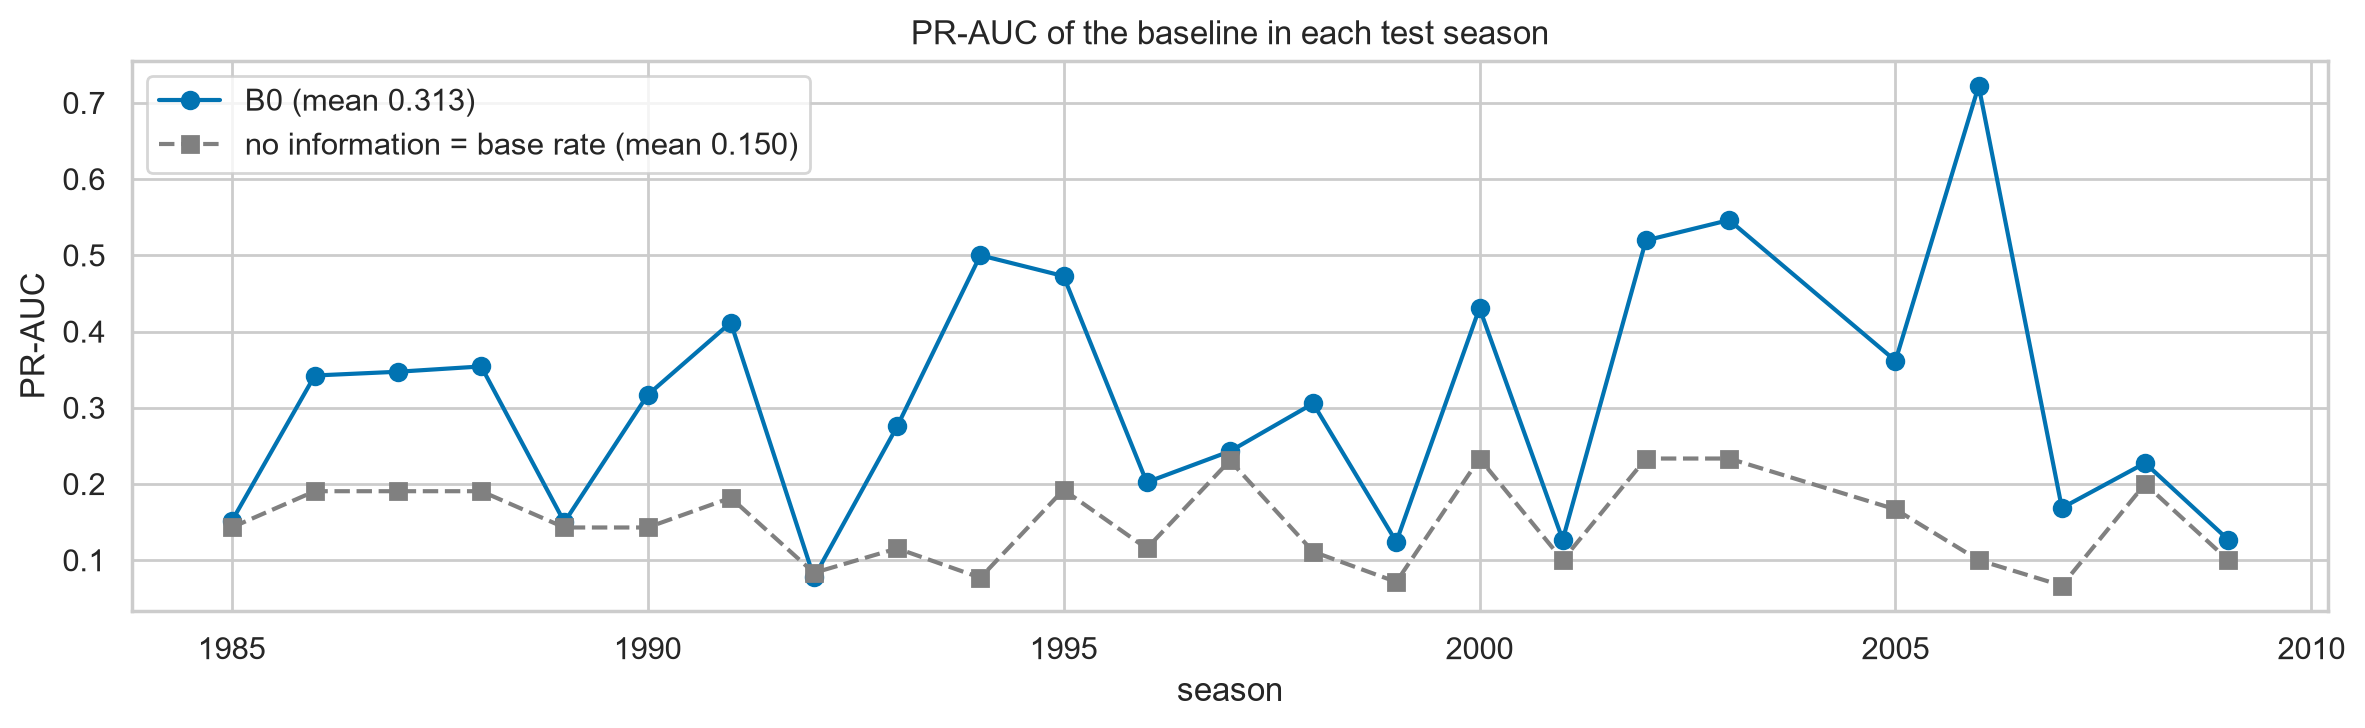

In [3]:
META = panel[["year", "tmID", "name", LABEL]]


def per_season(d):
    """PR-AUC, ROC-AUC, precision and recall of the K_FLAG teams with the highest score, for every season of `d` (columns y and score)."""
    rows = {}
    for year, g in d.groupby("year"):
        y, s = g["y"].to_numpy(), g["score"].to_numpy(float)
        top = np.argsort(-s, kind="stable")[:K_FLAG]
        rows[year] = {"pr_auc": average_precision_score(y, s), "roc_auc": roc_auc_score(y, s),
                      "precision@4": y[top].mean(), "caught": y[top].sum(), "positives": y.sum(), "base_rate": y.mean()}
    return pd.DataFrame(rows).T


def summary(preds):
    """Per-season scores and the summary measures of a table of predictions (year, tmID, score)."""
    d = META.merge(preds[["year", "tmID", "score"]], on=["year", "tmID"]).rename(columns={LABEL: "y"})
    ps = per_season(d)
    return ps, {"PR-AUC per season": ps["pr_auc"].mean(), "PR-AUC pooled": average_precision_score(d["y"], d["score"]),
                "ROC-AUC pooled": roc_auc_score(d["y"], d["score"]), "precision@4": ps["precision@4"].mean(),
                "recall@4": ps["caught"].sum() / ps["positives"].sum()}


def paired_stats(model, baseline, n_boot=10_000, seed=0):
    """Per-season differences of two series of scores: mean, bootstrap 95% interval over seasons, wins and Wilcoxon p-value."""
    d = (model - baseline).dropna().to_numpy()
    boot = np.random.default_rng(seed).choice(d, (n_boot, len(d))).mean(axis=1)
    return {"diff": d.mean(), "lo": np.percentile(boot, 2.5), "hi": np.percentile(boot, 97.5),
            "wins": int((d > 0).sum()), "n": len(d), "p": stats.wilcoxon(d).pvalue if np.any(d != 0) else np.nan}


def holm(p):
    """Holm-Bonferroni adjusted p-values (several models compared with the same reference)."""
    p = pd.Series(p, dtype=float)
    adjusted, running = {}, 0.0
    for i, key in enumerate(p.dropna().sort_values().index):
        running = max(running, min(1.0, (len(p.dropna()) - i) * p[key]))
        adjusted[key] = running
    return pd.Series(adjusted).reindex(p.index)


def compare(runs, reference):
    """One row per run: the summary measures and the paired comparison of its per-season PR-AUC with `reference` (a per-season series)."""
    rows = {}
    for name, preds in runs.items():
        ps, summ = summary(preds)
        r = paired_stats(ps["pr_auc"], reference)
        rows[name] = {**summ, "Δ PR-AUC": r["diff"], "CI low": r["lo"], "CI high": r["hi"], "better in": f"{r['wins']}/{r['n']}", "p": r["p"]}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table["p (Holm)"] = holm(table["p"])
    return table


def forest(ax, table, title, ref_label):
    """Mean per-season difference with the reference and its 95% interval, one line per row of `table`."""
    t = table.sort_values("Δ PR-AUC")
    for yi, (name, r) in enumerate(t.iterrows()):
        ax.errorbar(r["Δ PR-AUC"], yi, xerr=[[r["Δ PR-AUC"] - r["CI low"]], [r["CI high"] - r["Δ PR-AUC"]]], fmt="o", capsize=3, color="C0")
    ax.axvline(0, color="k", lw=0.8)
    ax.set_yticks(range(len(t)), t.index)
    ax.set(title=title, xlabel=f"PR-AUC per season minus {ref_label} (95% interval)")


test = panel[panel["year"].isin(TEST_YEARS)]
last_rank = test.groupby("year")["pts_pct_z_lag1"].rank(pct=True).fillna(0.5)       # 0 = worst ... 1 = best of its season
BASELINES = {"B0 worst last season first": pd.DataFrame({"year": test["year"], "tmID": test["tmID"], "score": -last_rank}),
             "no information": pd.DataFrame({"year": test["year"], "tmID": test["tmID"], "score": 0.0})}
B0_SEASONS = summary(BASELINES["B0 worst last season first"])[0]

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(B0_SEASONS.index, B0_SEASONS["pr_auc"], marker="o", label=f"B0 (mean {B0_SEASONS['pr_auc'].mean():.3f})")
ax.plot(B0_SEASONS.index, B0_SEASONS["base_rate"], marker="s", ls="--", color="grey", label=f"no information = base rate (mean {B0_SEASONS['base_rate'].mean():.3f})")
ax.set(title="PR-AUC of the baseline in each test season", xlabel="season", ylabel="PR-AUC")
ax.legend()
plt.tight_layout()
pd.DataFrame({name: summary(p)[1] for name, p in BASELINES.items()}).T.round(3)

- **B0 is far above no information on the main measure** (0.313 against 0.150): last season's record already ranks the teams. Its 4 flagged teams per season catch 25.5% of the replacements.
- **It varies a lot from season to season** (figure). With 2 to 7 replacements per test season, one team more or less found moves the PR-AUC of a season a lot, which is why every comparison is paired by season.
- The precision@4 of "no information" (0.07) comes from the alphabetical order in which tied teams are listed; in expectation it is the base rate, 0.15.

## 4. Sampling for development

Before tuning anything, two questions about the sample:
- **How much training data does a model need?** We start from a very small sample, the single season before the test season, and grow it to all the seasons before it. Each size is evaluated on the same 24 test seasons, with one fixed simple model (median imputation, standardisation and a logistic regression with the default penalty), so the curve shows the effect of the sample alone.
- **Which training window?** The EDA found that the league changed in the mid-1980s (01, 6.1) and that coach changes became rarer (23% to 15%). If the old seasons described a different league, a short window of recent seasons would beat all the seasons. The curve answers this too, and the test seasons don't choose anything here: whatever the curve says, the window of the next sections is decided below with a reason.

The code was also developed this way: with `QUICK = True` (section 0) the notebook runs on 3 test seasons and the first value of every grid, which takes seconds; the full run grows it to the 24 seasons and the complete grids.

In [4]:
def inner_splits(years):
    """The N_INNER last seasons of a training set, each predicted from the seasons before it (positions in the training rows)."""
    seasons = np.sort(np.unique(years))
    return [(np.flatnonzero(years < v), np.flatnonzero(years == v)) for v in seasons[-N_INNER:]]


def scores_of(estimator, X):
    """The score of the class 'replaced': a probability, or a decision value for the models without one."""
    if hasattr(estimator, "predict_proba"):
        return estimator.predict_proba(X)[:, 1]
    return estimator.decision_function(X)


def train_pr_auc(estimator, rows):
    """Mean per-season PR-AUC on the training seasons (for the analysis of overfitting)."""
    d = rows[["year"]].assign(y=rows[LABEL].to_numpy(), score=scores_of(estimator, rows[FEATURES].to_numpy(float)))
    return np.mean([average_precision_score(g["y"], g["score"]) for _, g in d.groupby("year") if g["y"].sum() > 0])


def run_fold(make, test_year, grid=None, window=None):
    """One outer split: the estimator built by `make(inner splits)`, tuned on `grid` inside the training seasons if given,
    trained on the `window` seasons before `test_year` (all of them if None), and its scores for `test_year`."""
    seasons = sorted(panel.loc[panel["year"] < test_year, "year"].unique())[-window if window else 0:]
    train, test = panel[panel["year"].isin(seasons)], panel[panel["year"] == test_year]
    X, y = train[FEATURES].to_numpy(float), train[LABEL].to_numpy()
    cv = inner_splits(train["year"].to_numpy())
    estimator, fold = make(cv), {"year": test_year, "train_seasons": len(seasons), "train_rows": len(train)}
    t0 = time.time()
    if grid:
        grid = {k: v[:1] for k, v in grid.items()} if QUICK else grid
        search = GridSearchCV(estimator, grid, cv=cv, scoring="average_precision", n_jobs=1).fit(X, y)
        estimator = search.best_estimator_
        fold.update(inner=search.best_score_, params=search.best_params_)
    else:
        estimator.fit(X, y)
    fold["seconds"] = time.time() - t0
    fold["train"] = train_pr_auc(estimator, train)
    preds = pd.DataFrame({"year": test_year, "tmID": test["tmID"].to_numpy(), "score": scores_of(estimator, test[FEATURES].to_numpy(float))})
    return {"preds": preds, "fold": fold, "estimator": estimator}


def walk_forward(make, grid=None, window=None):
    """Nested walk-forward evaluation: one outer split per test season, in parallel."""
    out = Parallel(n_jobs=-1)(delayed(run_fold)(make, year, grid, window) for year in TEST_YEARS)
    return {"preds": pd.concat([o["preds"] for o in out], ignore_index=True),
            "folds": pd.DataFrame([o["fold"] for o in out]).set_index("year"),
            "estimators": {o["fold"]["year"]: o["estimator"] for o in out}}

each window against all the seasons (per-season PR-AUC):
     diff     lo     hi  wins     n      p
1  -0.039 -0.110  0.038   7.0  24.0  0.143
2  -0.042 -0.115  0.043   6.0  24.0  0.046
3  -0.005 -0.064  0.058  10.0  24.0  0.643
5   0.026 -0.033  0.089  12.0  24.0  0.705
8   0.046 -0.008  0.101  16.0  24.0  0.121
11  0.016 -0.024  0.060  12.0  24.0  0.584 



,PR-AUC per season,PR-AUC pooled,ROC-AUC pooled,precision@4,recall@4,training rows (mean),seconds per season
1,0.309,0.185,0.537,0.198,0.202,25.750,0.049
2,0.305,0.219,0.562,0.198,0.202,51.125,0.033
3,0.343,0.229,0.576,0.219,0.223,76.125,0.029
5,0.374,0.257,0.637,0.240,0.245,125.000,0.031
8,0.394,0.275,0.646,0.260,0.266,195.042,0.035
11,0.364,0.259,0.632,0.250,0.255,260.833,0.035
all,0.348,0.249,0.638,0.292,0.298,491.375,0.037


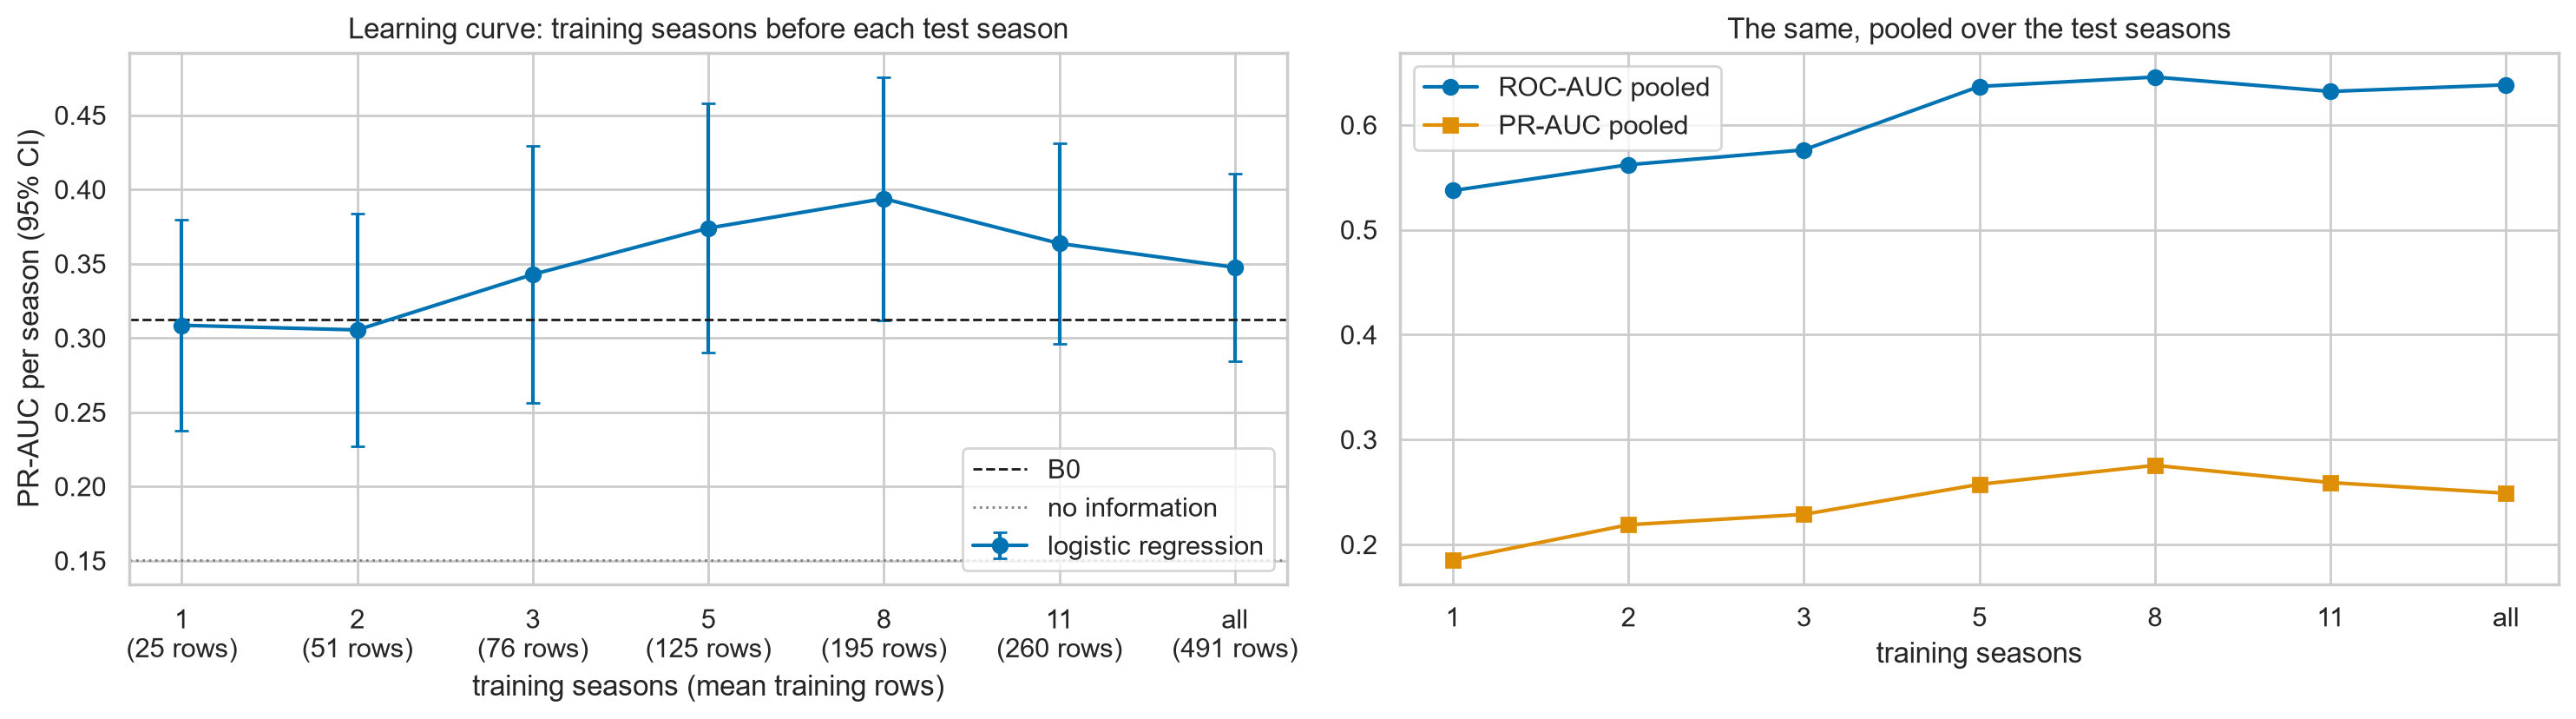

In [5]:
IMPUTERS = {"median": lambda: SimpleImputer(strategy="median"),
            "mean": lambda: SimpleImputer(strategy="mean"),
            "k-NN (15 neighbours)": lambda: KNNImputer(n_neighbors=15),
            "iterative (Bayesian ridge)": lambda: IterativeImputer(estimator=BayesianRidge(), max_iter=15, random_state=RANDOM_STATE)}


def clip_columns(X, n, limit=3.0):
    """Clip the first n columns (the standardised continuous features) at ±limit."""
    X = np.array(X, dtype=float, copy=True)
    X[:, :n] = np.clip(X[:, :n], -limit, limit)
    return X


def drop_outliers(X, y, cols, quantile=0.999):
    """Remove the training rows whose robust Mahalanobis distance on `cols` (Minimum Covariance Determinant, fitted on these
    training rows only) is beyond the chi-square quantile. Used as a sampler, so it never touches the rows that are predicted."""
    mcd = MinCovDet(random_state=RANDOM_STATE).fit(X[:, cols])
    keep = mcd.mahalanobis(X[:, cols]) <= stats.chi2.ppf(quantile, len(cols))
    return X[keep], y[keep]


def make_pipe(model, impute="median", outliers=None, sampler=None, select=None):
    """Imputation (continuous: standardise then impute; binary: most frequent), outlier treatment, resampling, feature selection, model.
    Every step is fitted on the training rows only, and the resampling and the outlier removal only act while fitting."""
    prep_step = ColumnTransformer([
        ("cont", SkPipeline([("scale", StandardScaler()), ("impute", IMPUTERS[impute]())]), list(range(N_CONT))),
        ("bin", SimpleImputer(strategy="most_frequent"), BIN_POS)])
    outlier_step = {"clip at ±3": FunctionTransformer(clip_columns, kw_args={"n": N_CONT}),
                    "drop from training": FunctionSampler(func=drop_outliers, kw_args={"cols": TEAM_POS}, validate=False)}.get(outliers, "passthrough")
    steps = [("prep", prep_step), ("outliers", outlier_step), ("sample", sampler if sampler is not None else "passthrough")]
    if isinstance(select, tuple):                     # a filter followed by a wrapper
        steps += [("select", select[0]), ("select2", select[1])]
    else:
        steps += [("select", select if select is not None else "passthrough")]
    # the cache identifies a step by its parameters, which it can't do for the functions of this notebook inside the parallel
    # workers; the outlier treatments are only used without tuning, where the cache saves nothing
    return Pipeline(steps + [("model", model)], memory=CACHE if outliers is None else None)


def logistic(**kw):
    return LogisticRegression(C=1.0, max_iter=5000, **kw)


WINDOWS = [1, 2, 3, 5, 8, 11, None] if not QUICK else [2, None]
curve = {w: walk_forward(lambda cv: make_pipe(logistic()), window=w) for w in WINDOWS}
curve_table = pd.DataFrame({("all" if w is None else w): {**summary(r["preds"])[1], "training rows (mean)": r["folds"]["train_rows"].mean(),
                                                          "seconds per season": r["folds"]["seconds"].mean()}
                            for w, r in curve.items()}).T
curve_seasons = pd.DataFrame({("all" if w is None else w): summary(r["preds"])[0]["pr_auc"] for w, r in curve.items()})
curve_vs_all = pd.DataFrame({w: paired_stats(curve_seasons[w], curve_seasons["all"]) for w in curve_seasons if w != "all"}).T

fig, ax = plt.subplots(1, 2, figsize=(15, 4.3))
x = np.arange(len(curve_table))
ax[0].errorbar(x, curve_table["PR-AUC per season"], yerr=1.96 * curve_seasons.sem().to_numpy(), marker="o", capsize=3, label="logistic regression")
ax[0].axhline(B0_SEASONS["pr_auc"].mean(), color="k", ls="--", lw=1, label="B0")
ax[0].axhline(B0_SEASONS["base_rate"].mean(), color="grey", ls=":", lw=1, label="no information")
ax[0].set_xticks(x, [f"{w}\n({int(n)} rows)" for w, n in zip(curve_table.index, curve_table["training rows (mean)"])])
ax[0].set(title="Learning curve: training seasons before each test season", xlabel="training seasons (mean training rows)", ylabel="PR-AUC per season (95% CI)")
ax[0].legend(loc="lower right")
ax[1].plot(x, curve_table["ROC-AUC pooled"], marker="o", label="ROC-AUC pooled")
ax[1].plot(x, curve_table["PR-AUC pooled"], marker="s", label="PR-AUC pooled")
ax[1].set_xticks(x, curve_table.index)
ax[1].set(title="The same, pooled over the test seasons", xlabel="training seasons")
ax[1].legend()
plt.tight_layout()
print("each window against all the seasons (per-season PR-AUC):")
print(curve_vs_all.round(3).to_string(), "\n")
curve_table.round(3)

- **A very small sample is not enough.** With 1 or 2 training seasons (26 and 51 rows, about 4 and 8 replacements) the logistic regression is at the level of B0 (0.31 against 0.313). It needs about 5 seasons (125 rows, about 20 replacements) to pass it clearly (0.374).
- **From 5 seasons on, the curve is flat within the noise.** 8 seasons score best (0.394), 11 and all of them a little less (0.364 and 0.348), but no window is significantly better than all the seasons: the best, 8, is better in 16 of the 24 seasons (p = 0.12). All the seasons also flag the most replacements (precision@4 0.292 against 0.260). The old seasons don't hurt in a way that can be measured, even if the league changed in the mid-1980s.
- **Decision: train on all the seasons before the test season.** It is the simplest choice and uses the most data, and picking the best of seven windows on the test seasons would make them part of the training. Tuning the window inside the training seasons is future work.
- **Time is not a constraint here**: the logistic regression trains in 0.04 s per season at any size.

## 5. Data preparation inside the training seasons

Each subsection changes **one** step of a reference pipeline (median imputation, no outlier treatment, no resampling, all the features, a logistic regression) and compares the variants with the reference on the 24 test seasons. These comparisons describe the effect of each option. They don't choose it: comparing options on the test seasons and then keeping the best would make the test seasons part of the training. In section 6 the options are tuned like hyperparameters, inside the training seasons of each split.

### 5.1 Missing values

The missing values are structural (02, section 9): the history of the 15 new franchises and of the second seasons, and the career win % of the 113 coaches in their first NHL job. Their meaning is already in the features (`is_new_team`, `first_job`), so the filled value only has to be neutral. Four imputers, all fitted on the training rows of each split: the median and the mean (simple), the mean of the 15 most similar team-seasons (k-NN), and a model-based one, `IterativeImputer`, which predicts each feature with missing values from the others by a Bayesian ridge regression and iterates. The continuous features are standardised first, so that the k-NN distance weighs them equally. The binary features get the most frequent value.

In [6]:
REFERENCE = lambda cv: make_pipe(logistic())
imputation = {name: walk_forward(lambda cv, name=name: make_pipe(logistic(), impute=name))["preds"] for name in IMPUTERS}
ref_seasons = summary(imputation["median"])[0]["pr_auc"]
table_51 = compare(imputation, ref_seasons)

# what the model-based imputer fills in for the first-time coaches, fitted on all the seasons before 1985 (the first training set)
first = panel[panel["year"] < ERA_SPLIT]
filled = make_pipe(logistic(), impute="iterative (Bayesian ridge)").named_steps["prep"].fit(first[FEATURES].to_numpy(float)).transform(
    panel.loc[panel["first_job"] == 1, FEATURES].to_numpy(float))
scale = StandardScaler().fit(first[CONT].to_numpy(float))
win_pct = filled[:, CONT.index("career_win_pct")] * scale.scale_[CONT.index("career_win_pct")] + scale.mean_[CONT.index("career_win_pct")]
print(f"career win % filled for the first-time coaches by the iterative imputer: mean {win_pct.mean():.3f}, sd {win_pct.std():.3f} "
      f"(median imputation: {first['career_win_pct'].median():.3f} for all; experienced coaches: mean {first['career_win_pct'].mean():.3f}, sd {first['career_win_pct'].std():.3f})")
table_51.round(3)

career win % filled for the first-time coaches by the iterative imputer: mean 0.392, sd 0.081 (median imputation: 0.431 for all; experienced coaches: mean 0.427, sd 0.111)


,PR-AUC per season,PR-AUC pooled,ROC-AUC pooled,precision@4,recall@4,Δ PR-AUC,CI low,CI high,better in,p,p (Holm)
median,0.348,0.249,0.638,0.292,0.298,0.000,0.000,0.000,0/24,NaN,NaN
mean,0.347,0.249,0.638,0.292,0.298,-0.000,-0.001,0.000,1/24,0.285,0.855
k-NN (15 neighbours),0.354,0.258,0.639,0.292,0.298,0.006,-0.012,0.026,12/24,0.601,0.956
iterative (Bayesian ridge),0.354,0.260,0.637,0.292,0.298,0.007,-0.009,0.024,11/24,0.478,0.956


- **The imputer makes no difference.** The four are within 0.007 of each other (every p ≥ 0.28, 0.85 or more after Holm), with the same precision@4. The missing values are few, and their meaning is already in `first_job` and `is_new_team`, so the model learns it from the flags whatever value is filled in.
- **The model-based imputer still learns something sensible.** For the first-time coaches it fills a career win % of 0.392 on average, below the experienced coaches (0.427) and the median (0.431). It predicts the win % from the team, and first-time coaches take over weaker teams: last season 0.31 standard deviations below the league, with a starting roster 0.39 below. A coach's win % follows the team's record (0.7 in the heatmap of 02, section 7).
- Section 6 still lets the training seasons choose between the median and the iterative imputer.

### 5.2 Outliers

02 (section 8) kept every row and fixed the one kind of extreme value that was noise (the goalies' rates). Two treatments are left for the models, both fitted on the training rows only: **clipping** the standardised continuous features at ±3 (a simple, technical treatment for the models that depend on the scale), and **removing the multivariate outliers from the training rows**: the robust Mahalanobis distance on the team and roster z-scores (Minimum Covariance Determinant), with the rows beyond the 99.9% chi-square quantile dropped while fitting. The predicted rows are never touched, because their extreme teams are part of what has to be predicted.

In [7]:
outlier_runs = {name: walk_forward(lambda cv, name=name: make_pipe(logistic(), outliers=name))["preds"]
                for name in [None, "clip at ±3", "drop from training"]}
outlier_runs = {("none" if k is None else k): v for k, v in outlier_runs.items()}
table_52 = compare(outlier_runs, ref_seasons)

first_X = make_pipe(logistic()).named_steps["prep"].fit_transform(first[FEATURES].to_numpy(float))
n_dropped = len(first_X) - len(drop_outliers(first_X, first[LABEL].to_numpy(), TEAM_POS)[0])
print(f"rows that 'drop from training' removes from the first training set (1974-1984): {n_dropped} of {len(first_X)}; "
      f"values that the clip changes there: {int((np.abs(first_X[:, :N_CONT]) > 3).sum())}")
table_52.round(3)

rows that 'drop from training' removes from the first training set (1974-1984): 2 of 215; values that the clip changes there: 22


,PR-AUC per season,PR-AUC pooled,ROC-AUC pooled,precision@4,recall@4,Δ PR-AUC,CI low,CI high,better in,p,p (Holm)
none,0.348,0.249,0.638,0.292,0.298,0.000,0.000,0.000,0/24,NaN,NaN
clip at ±3,0.360,0.253,0.639,0.302,0.309,0.013,-0.007,0.039,11/24,0.463,0.921
drop from training,0.353,0.253,0.640,0.292,0.298,0.005,-0.004,0.017,10/24,0.460,0.921


- **Neither treatment changes the result significantly.** Clipping at ±3 gains 0.013 (better in 11 of 24 seasons, p = 0.46) and removing the multivariate outliers from the training rows 0.005 (p = 0.46). The extreme values are few (in the first training set the clip changes 22 values and the removal drops 2 of the 215 rows), and a regularised logistic regression is not dominated by them.
- They are left out of section 6: they add nothing measurable, and the grid is already large.

### 5.3 Imbalanced classes

About 1 team in 7 replaces its coach in the test seasons (1 in 4 to 1 in 5 in the early training seasons). Five ways of treating the imbalance, all **inside the training rows of each split**: the resampled rows are created or removed while fitting, so they never reach a validation or test season.
- **none**;
- **class weights**: each positive weighs as much as `n_negative / n_positive` negatives in the loss;
- **random over-sampling** of the positives and **random under-sampling** of the negatives, until the classes are balanced;
- **SMOTE-NC**: new positives interpolated between a positive and one of its 5 nearest positive neighbours. The NC version (nominal and continuous) gives the binary features the most frequent value among the neighbours, instead of an impossible value such as 0.4 of a new coach.

The effect depends on the algorithm, so they are compared with a logistic regression and with a random forest (200 trees, leaves of at least 10 rows).

In [8]:
def balanced_pipe(model_factory, name):
    """The reference pipeline with one way of treating the imbalance."""
    if name == "class weights":
        return make_pipe(model_factory(class_weight="balanced"))
    sampler = {"none": None, "random over-sampling": RandomOverSampler(random_state=RANDOM_STATE),
               "random under-sampling": RandomUnderSampler(random_state=RANDOM_STATE),
               "SMOTE-NC": SMOTENC(categorical_features=BIN_POS, random_state=RANDOM_STATE)}[name]
    return make_pipe(model_factory(), sampler=sampler)


forest_model = lambda **kw: RandomForestClassifier(n_estimators=200, min_samples_leaf=10, random_state=RANDOM_STATE, n_jobs=1, **kw)
BALANCE = ["none", "class weights", "random over-sampling", "random under-sampling", "SMOTE-NC"]
balance_runs = {}
for model_name, factory in [("logistic", logistic), ("random forest", forest_model)]:
    for name in BALANCE:
        balance_runs[(model_name, name)] = walk_forward(lambda cv, f=factory, n=name: balanced_pipe(f, n))["preds"]
table_53 = pd.concat({m: compare({n: balance_runs[(m, n)] for n in BALANCE}, summary(balance_runs[(m, "none")])[0]["pr_auc"])
                      for m in ["logistic", "random forest"]})
table_53.round(3)

PR-AUC per season  PR-AUC pooled  ROC-AUC pooled  precision@4  recall@4  Δ PR-AUC  CI low  CI high  \
logistic      none                               0.348          0.249           0.638        0.292     0.298     0.000   0.000    0.000   
              class weights                      0.344          0.240           0.630        0.281     0.287    -0.004  -0.022    0.018   
              random over-sampling               0.373          0.257           0.643        0.312     0.319     0.026  -0.011    0.067   
              random under-sampling              0.344          0.243           0.655        0.219     0.223    -0.004  -0.043    0.037   
              SMOTE-NC                           0.370          0.236           0.636        0.302     0.309     0.023  -0.017    0.066   
random forest none                               0.345          0.218           0.620        0.250     0.255     0.000   0.000    0.000   
              class weights                      0.337          0.219           0.627        0.240     0.245    -0.009  -0.060    0.036   
              random over-sampling               0.326          0.224           0.619        0.250     0.255    -0.019  -0.091    0.041   
              random under-sampling              0.351          0.246           0.656        0.240     0.245     0.006  -0.047    0.060   
              SMOTE-NC                           0.383          0.233           0.648        0.271     0.277     0.038  -0.040    0.112   

                                    better in      p  p (Holm)  
logistic      none                       0/24    NaN       NaN  
              class weights              8/24  0.264     0.793  
              random over-sampling      14/24  0.088     0.353  
              random under-sampling     12/24  0.922     1.000  
              SMOTE-NC                  12/24  0.643     1.000  
random forest none                       0/24    NaN       NaN  
              class weights             13/24  0.833     1.000  
              random over-sampling      13/24  0.989     1.000  
              random under-sampling     14/24  0.855     1.000  
              SMOTE-NC                  16/24  0.188     0.750

- **No treatment is significantly better than none**, for either algorithm (every p ≥ 0.35 after Holm). The ranking measures don't depend on a threshold, and moving the threshold is most of what resampling does.
- **Class weights change nothing for the logistic regression** (−0.004): weighting the positives mostly shifts the intercept, which doesn't change the order of the teams.
- **Under-sampling throws information away.** It keeps about a quarter of the negatives, and the precision of the 4 teams flagged falls from 0.29 to 0.22 for the logistic regression.
- **Over-sampling helps a little where it adds something new.** For the logistic regression random over-sampling and SMOTE-NC both gain (+0.026 and +0.023): more positives weigh more against the penalty. For the forest only SMOTE-NC gains, and the most of all (+0.038, better in 16 of 24 seasons), because its interpolated positives fill the space between the real ones; duplicated rows only let the deep trees memorise the same positives (−0.019).
- **The pooled PR-AUC can fall when the per-season one rises** (SMOTE-NC for the logistic regression: 0.236 against 0.249). Resampling changes the level of the probabilities from one training set to the next, so the scores of different seasons become less comparable. This is why the main measure is per season.
- Section 6 lets the training seasons choose between SMOTE-NC and no resampling.

### 5.4 Feature selection

The 17 candidates were only filtered for redundancy (02, section 7). Four ways of selecting them, all fitted on the training rows of each split:
- **all** the candidates;
- **filter:** the k features with the highest mutual information with the label (k from 3 to 12, chosen by the inner validation seasons). Mutual information also sees relations that are not linear, and it doesn't use any model;
- **wrapper:** forward sequential selection with the logistic regression itself: starting from nothing, it adds the feature that most improves the PR-AUC of the inner validation seasons, and stops when no feature improves it by 0.002 or more;
- **filter then wrapper:** the wrapper on the 10 features with the highest mutual information (cheaper, and less exposed to the noise of many candidates).

features kept per split: filter (mutual information, k tuned): 9.9, wrapper (forward selection): 4.8, filter then wrapper: 4.0


,PR-AUC per season,PR-AUC pooled,ROC-AUC pooled,precision@4,recall@4,Δ PR-AUC,CI low,CI high,better in,p,p (Holm)
all,0.348,0.249,0.638,0.292,0.298,0.000,0.000,0.00,0/24,NaN,NaN
"filter (mutual information, k tuned)",0.349,0.234,0.623,0.240,0.245,0.002,-0.035,0.04,12/24,0.966,0.966
wrapper (forward selection),0.299,0.202,0.605,0.208,0.213,-0.048,-0.095,-0.00,9/24,0.060,0.181
filter then wrapper,0.322,0.205,0.617,0.260,0.266,-0.025,-0.064,0.01,9/24,0.264,0.529


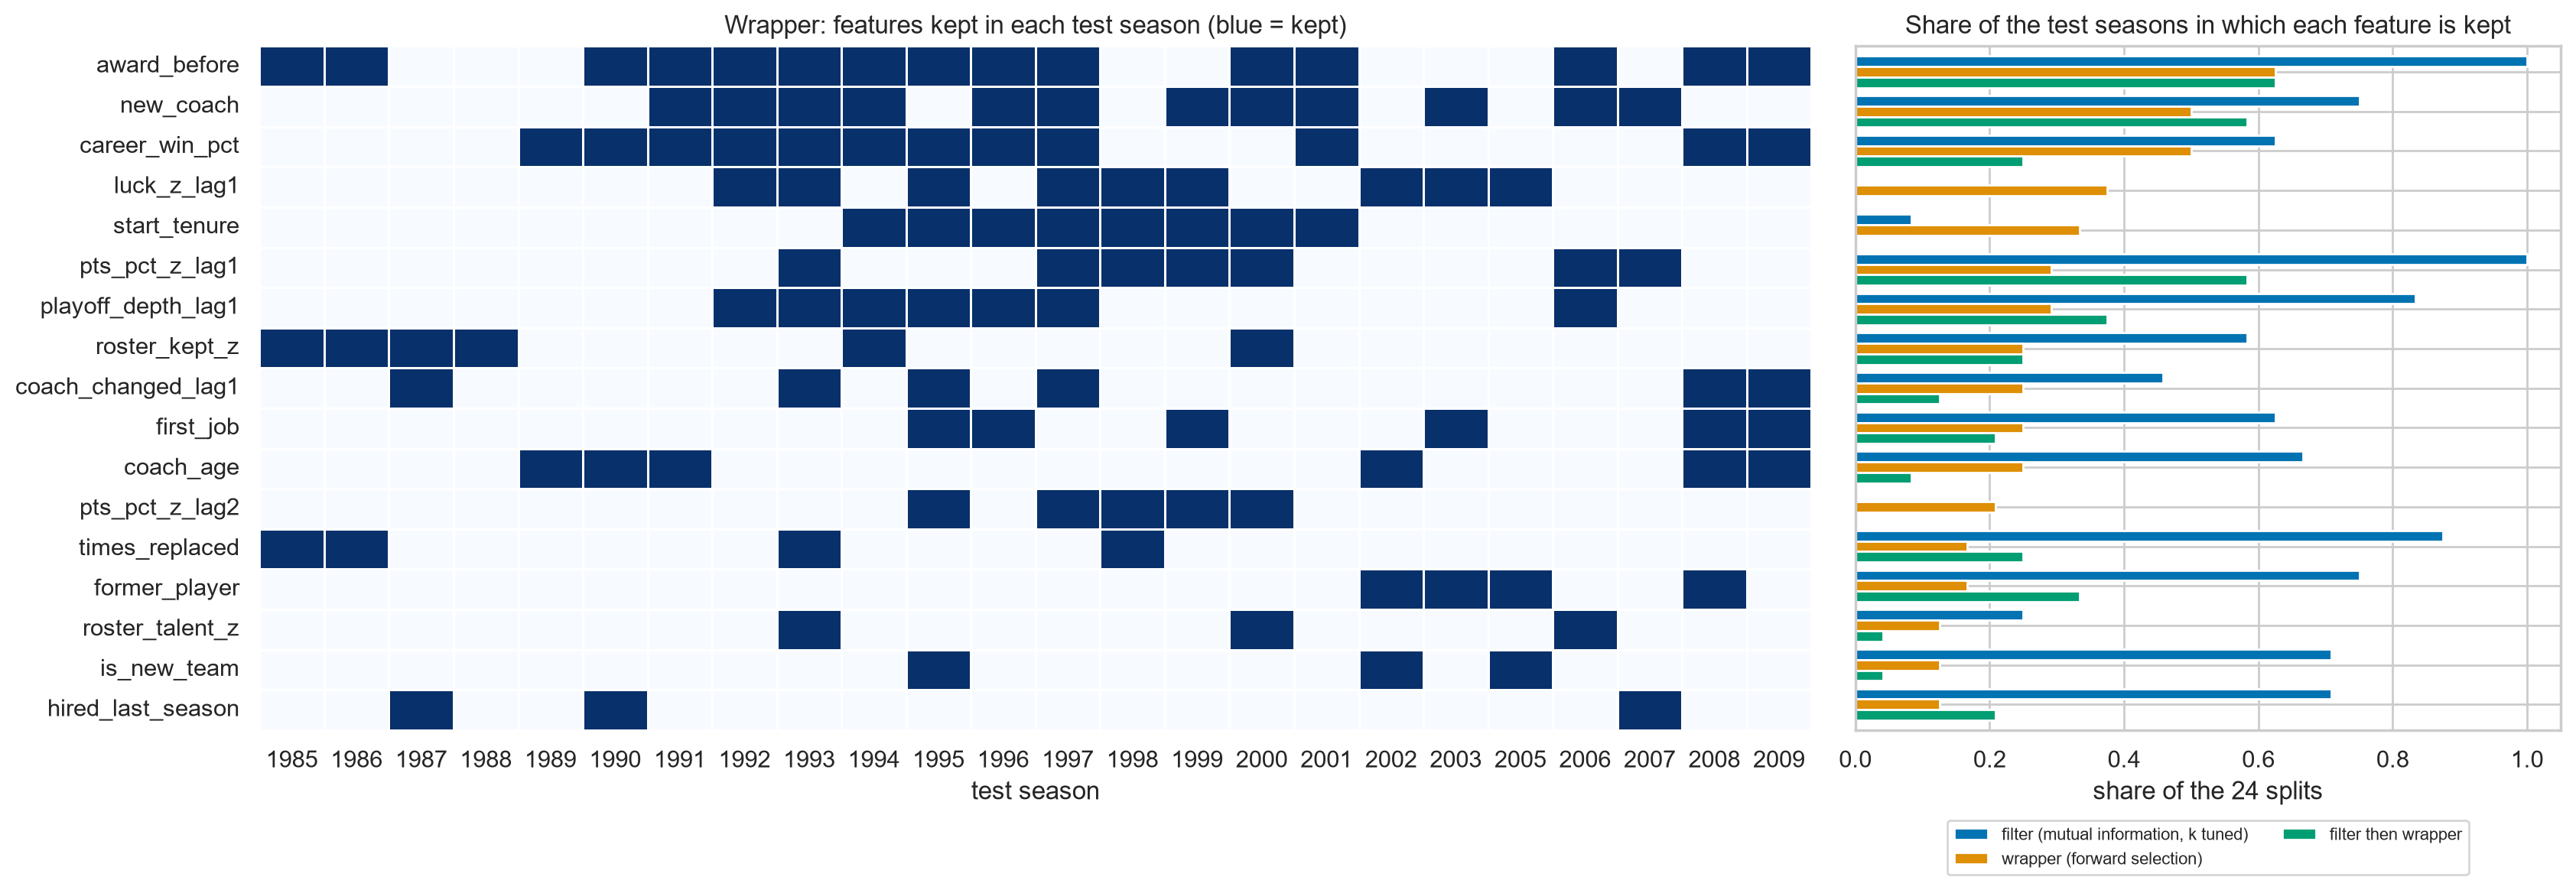

In [9]:
BIN_MASK = np.array([i in BIN_POS for i in range(len(FEATURES))])
mi = partial(mutual_info_classif, discrete_features=BIN_MASK, random_state=RANDOM_STATE)
wrapper = lambda cv: SequentialFeatureSelector(logistic(), direction="forward", n_features_to_select="auto", tol=0.002,
                                               scoring="average_precision", cv=cv)
selection_runs = {
    "all": walk_forward(REFERENCE),
    "filter (mutual information, k tuned)": walk_forward(lambda cv: make_pipe(logistic(), select=SelectKBest(mi, k=8)),
                                                         grid={"select__k": [3, 5, 8, 12]}),
    "wrapper (forward selection)": walk_forward(lambda cv: make_pipe(logistic(), select=wrapper(cv))),
    "filter then wrapper": walk_forward(lambda cv: make_pipe(logistic(), select=(SelectKBest(mi, k=10), wrapper(cv)))),
}
table_54 = compare({n: r["preds"] for n, r in selection_runs.items()}, ref_seasons)


def selected(run):
    """For each test season, the features kept by the selection step of the fitted pipeline (1 = kept)."""
    rows = {}
    for year, est in run["estimators"].items():
        mask = est.named_steps["select"].get_support().copy()
        if "select2" in est.named_steps:                      # the wrapper keeps a subset of the filtered features
            mask[np.flatnonzero(mask)[~est.named_steps["select2"].get_support()]] = False
        rows[year] = mask.astype(int)
    return pd.DataFrame(rows, index=FEATURES)


kept = {n: selected(selection_runs[n]) for n in ["filter (mutual information, k tuned)", "wrapper (forward selection)", "filter then wrapper"]}
fig, ax = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [2.2, 1]})
order = kept["wrapper (forward selection)"].mean(axis=1).sort_values(ascending=False).index
sns.heatmap(kept["wrapper (forward selection)"].loc[order], ax=ax[0], cmap="Blues", cbar=False, linewidths=0.5, linecolor="white")
ax[0].set(title="Wrapper: features kept in each test season (blue = kept)", xlabel="test season", ylabel="")
pd.DataFrame({n: k.loc[order].mean(axis=1) for n, k in kept.items()}).plot.barh(ax=ax[1], width=0.8)
ax[1].invert_yaxis()
ax[1].set(title="Share of the test seasons in which each feature is kept", xlabel="share of the 24 splits", yticklabels=[])
ax[1].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.tight_layout()
print("features kept per split: " + ", ".join(f"{n}: {k.sum().mean():.1f}" for n, k in kept.items()))
table_54.round(3)

- **The filter keeps the result with about 10 of the 17 features** (+0.002, p = 0.97). It always keeps last season's points % and an award before, and almost always the times the coach was replaced before and the playoff depth.
- **The wrapper is worse than keeping every feature** (−0.048, better in only 9 of 24 seasons, p = 0.06, 0.18 after Holm), and so is the filter followed by the wrapper (−0.025). The wrapper keeps 4 to 5 features chosen greedily on 6 validation seasons with 2 to 9 replacements each, so it fits the noise of those seasons. The features it keeps change from one split to the next (heatmap): only an award before, a new coach and the career win % are kept in half the splits or more.
- **For a task with so few events**, a cheap filter that keeps most features and a regularised model beat a search over subsets. Section 6 lets the training seasons choose between the filter (8 features) and all the features.

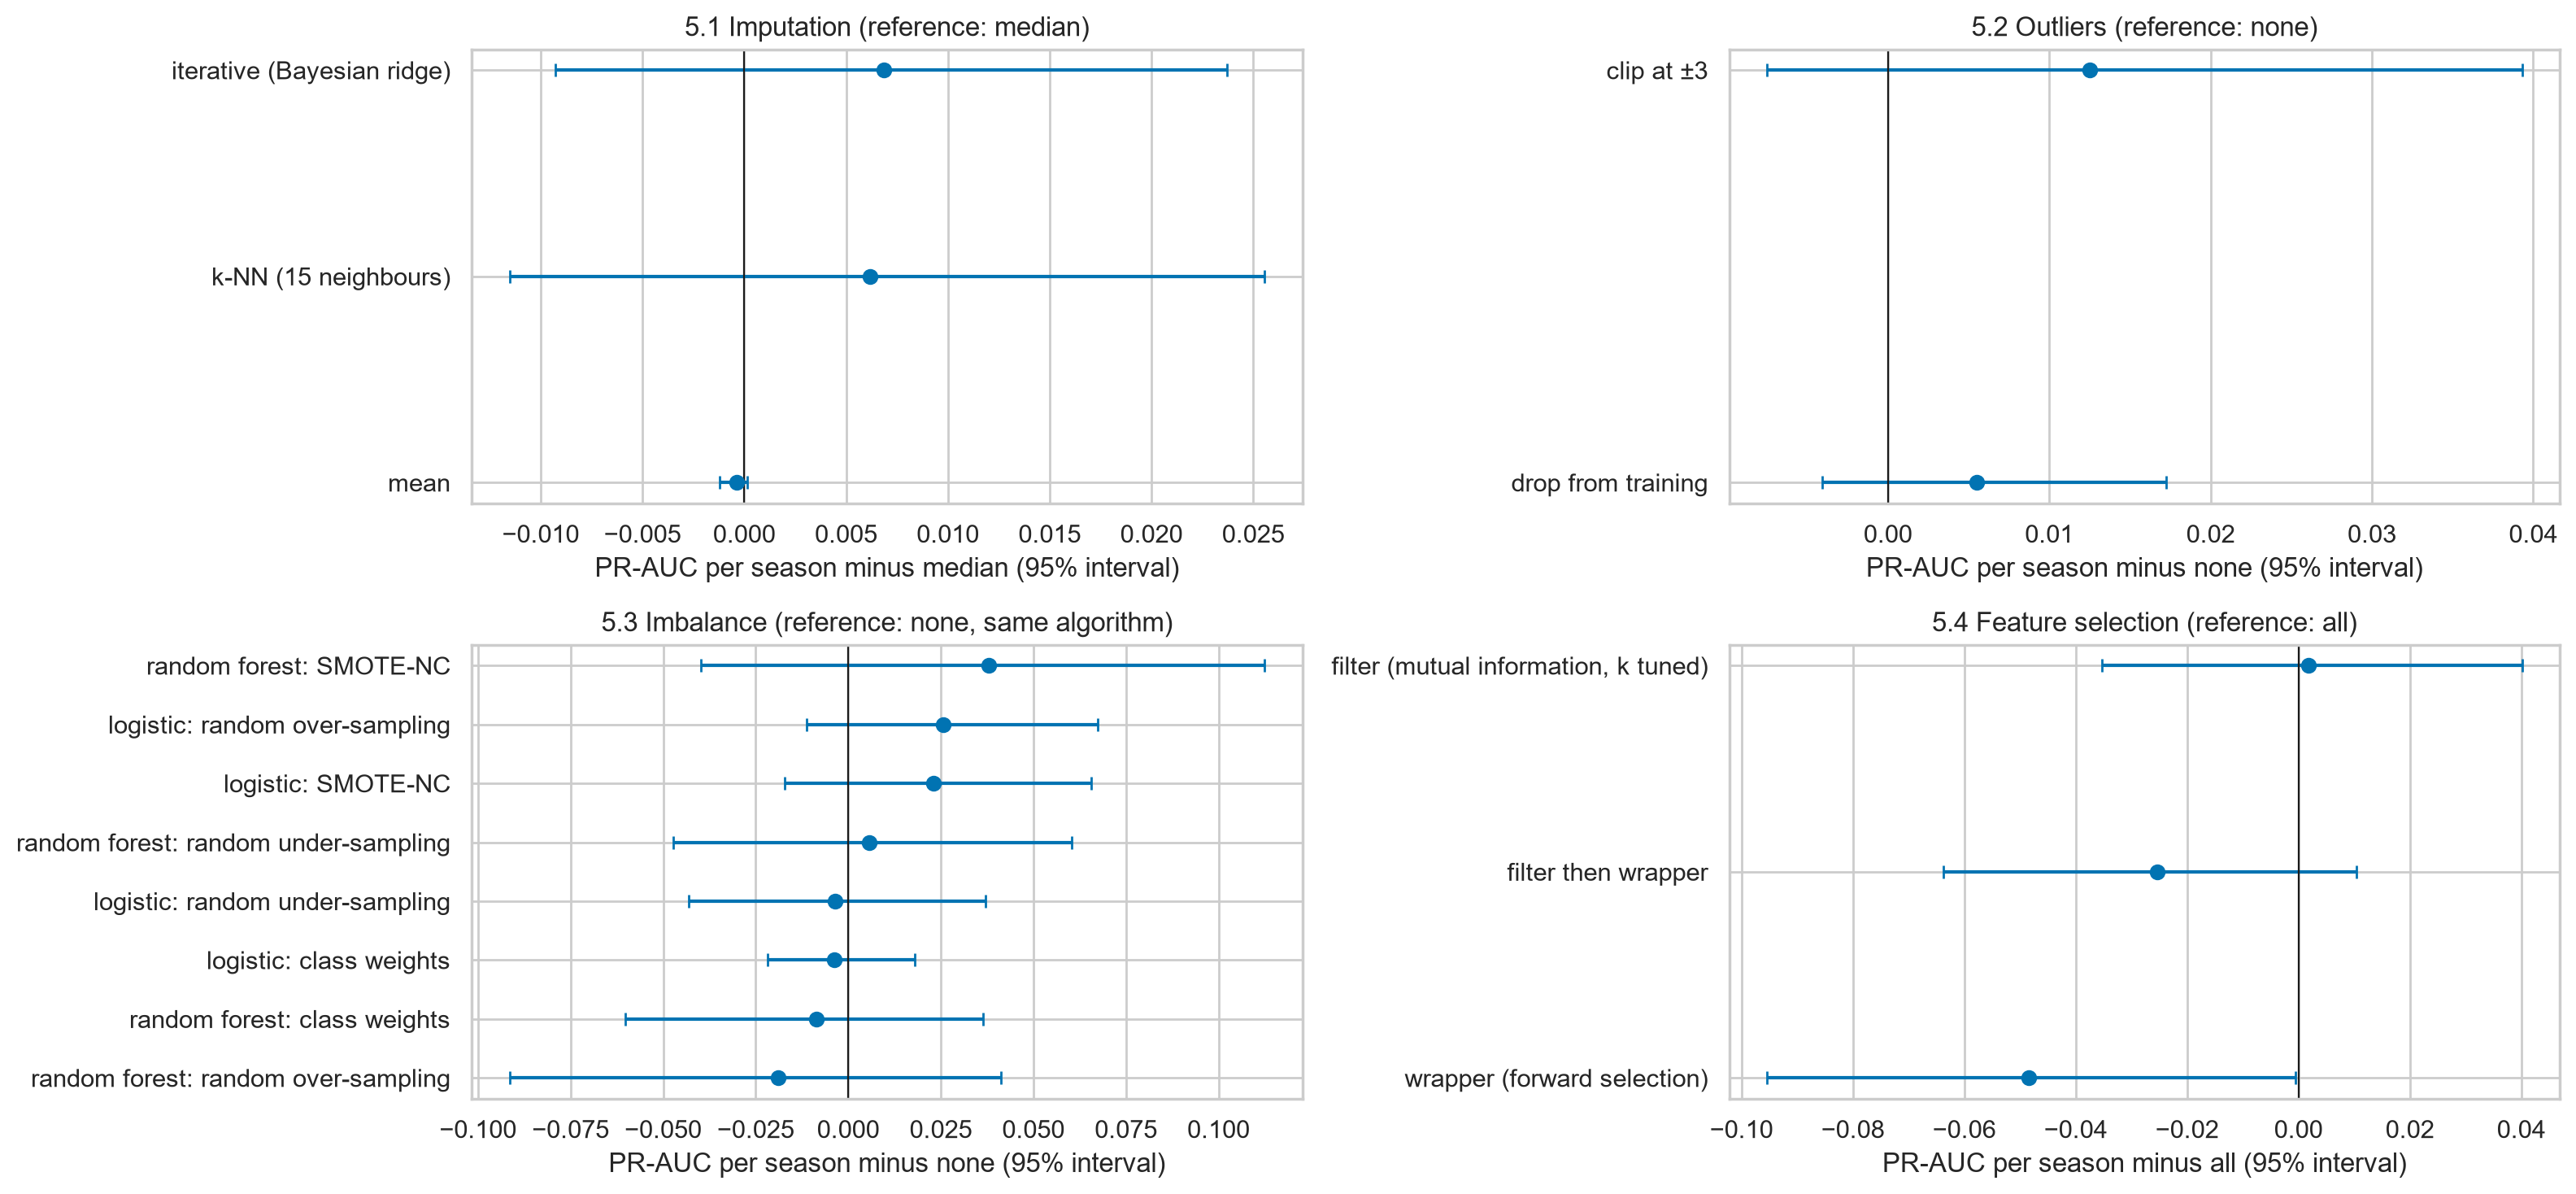

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(16, 7.5))
forest(axes[0, 0], table_51.drop(index="median"), "5.1 Imputation (reference: median)", "median")
forest(axes[0, 1], table_52.drop(index="none"), "5.2 Outliers (reference: none)", "none")
t53 = table_53.drop(index="none", level=1)
t53.index = [f"{m}: {n}" for m, n in t53.index]
forest(axes[1, 0], t53, "5.3 Imbalance (reference: none, same algorithm)", "none")
forest(axes[1, 1], table_54.drop(index="all"), "5.4 Feature selection (reference: all)", "all")
plt.tight_layout()

## 6. Algorithms and their tuning

Eight algorithms with different language biases, as in 03 for task (a):

| Family | What it can represent | Algorithm |
|---|---|---|
| Linear | a weighted sum of the features, turned into a probability | logistic regression |
| Tree | a few rules that cut one feature at a time (white-box) | decision tree |
| Bagging | the average of many deep trees | random forest |
| Boosting | shallow trees added one by one, each correcting the others | gradient boosting |
| Kernel | smooth functions of the distance to the training points | SVM (RBF kernel) |
| Instances | the share of replacements among the most similar past team-seasons | k-NN |
| Probabilistic | class densities with independent features | Gaussian naive Bayes |
| Neural network | smooth non-linear combinations of the features | MLP |

**Tuning.** A grid search inside every walk-forward split, scored by the PR-AUC of the 6 inner validation seasons, as in 03. The grid of every algorithm has its own hyperparameters and three data-preparation choices of section 5, so that the training seasons choose them and the test seasons don't: the imputer (median or iterative), SMOTE-NC or no resampling, and the filter (8 features by mutual information, or all). The outlier treatments are left out: section 5.2 found no effect, and the scale-dependent models already see standardised features.

In [11]:
PREP_GRID = {"prep__cont__impute": [SimpleImputer(strategy="median"),
                                    IterativeImputer(estimator=BayesianRidge(), max_iter=15, random_state=RANDOM_STATE)],
             "sample": ["passthrough", SMOTENC(categorical_features=BIN_POS, random_state=RANDOM_STATE)],
             "select": ["passthrough", SelectKBest(mi, k=8)]}
ALGORITHMS = {   # name: (family, model, its own grid)
    "logistic regression": ("linear", logistic(), {"model__C": [0.01, 0.1, 1, 10]}),
    "decision tree": ("tree", DecisionTreeClassifier(random_state=RANDOM_STATE), {"model__max_depth": [2, 3, 5], "model__min_samples_leaf": [10, 30]}),
    "random forest": ("bagging", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1),
                      {"model__min_samples_leaf": [5, 20], "model__max_features": [0.33, 0.66]}),
    "gradient boosting": ("boosting", GradientBoostingClassifier(subsample=0.8, random_state=RANDOM_STATE),
                          {"model__n_estimators": [50, 150], "model__learning_rate": [0.03], "model__max_depth": [1, 2]}),
    "SVM (RBF)": ("kernel", SVC(kernel="rbf"), {"model__C": [0.1, 1], "model__gamma": [0.01, 0.05]}),
    "k-NN": ("instances", KNeighborsClassifier(weights="distance"), {"model__n_neighbors": [15, 40]}),
    "Gaussian naive Bayes": ("probabilistic", GaussianNB(), {}),
    "MLP": ("neural network", MLPClassifier(hidden_layer_sizes=(8,), max_iter=2000, random_state=RANDOM_STATE), {"model__alpha": [1.0, 10.0]}),
}
TUNED = {}
for name, (_, model, grid) in ALGORITHMS.items():
    t0 = time.time()
    TUNED[name] = walk_forward(lambda cv, m=model: make_pipe(m), grid={**PREP_GRID, **grid})
    print(f"{name:22s} {int(np.prod([len(v) for v in {**PREP_GRID, **grid}.values()])):3d} combinations  {time.time() - t0:5.0f} s")
shutil.rmtree(CACHE_DIR, ignore_errors=True)        # the rest of the notebook only uses the fitted models

logistic regression     32 combinations     30 s


decision tree           48 combinations     35 s


random forest           32 combinations    239 s


gradient boosting       32 combinations     81 s


SVM (RBF)               32 combinations     31 s


k-NN                    16 combinations     13 s


Gaussian naive Bayes     8 combinations      5 s


MLP                     16 combinations    140 s


In [12]:
def label(v):
    """A short name for a grid value (an estimator or a number)."""
    if isinstance(v, str):
        return "none" if v == "passthrough" else v
    if isinstance(v, SimpleImputer):
        return "median"
    if isinstance(v, IterativeImputer):
        return "iterative"
    if isinstance(v, SMOTENC):
        return "SMOTE-NC"
    if isinstance(v, SelectKBest):
        return f"filter k={v.k}"
    return f"{v:g}" if isinstance(v, (int, float, np.number)) else str(v)


SHORT = {"prep__cont__impute": "imputer", "sample": "resampling", "select": "selection"}
choices = {}
for name, run in TUNED.items():
    p = pd.DataFrame(list(run["folds"]["params"])).rename(columns=lambda c: SHORT.get(c, c.replace("model__", ""))).map(label)
    choices[name] = {c: f"{p[c].mode()[0]} ({(p[c] == p[c].mode()[0]).mean():.0%})" for c in p}
pd.DataFrame(choices).T.fillna("").rename_axis("most chosen value (share of the splits)")

,C,imputer,resampling,selection,max_depth,min_samples_leaf,max_features,learning_rate,n_estimators,gamma,n_neighbors,alpha
most chosen value (share of the splits),,,,,,,,,,,,
logistic regression,0.1 (42%),iterative (54%),SMOTE-NC (62%),none (79%),,,,,,,,
decision tree,,median (71%),SMOTE-NC (54%),none (54%),5 (79%),10 (79%),,,,,,
random forest,,iterative (58%),SMOTE-NC (67%),none (62%),,20 (58%),0.66 (58%),,,,,
gradient boosting,,median (75%),SMOTE-NC (58%),none (83%),2 (96%),,,0.03 (100%),50 (62%),,,
SVM (RBF),1 (79%),median (54%),SMOTE-NC (71%),none (71%),,,,,,0.01 (75%),,
k-NN,,iterative (75%),none (71%),none (58%),,,,,,,15 (54%),
Gaussian naive Bayes,,iterative (50%),SMOTE-NC (58%),none (58%),,,,,,,,
MLP,,iterative (54%),SMOTE-NC (62%),none (71%),,,,,,,,1 (71%)


- **Tuning the 8 algorithms takes about 10 minutes** (24 test seasons, 8 to 48 combinations, 6 validation seasons each). The random forest takes the largest share (about 110 s per season); the timings change a little from run to run.
- **The training seasons choose SMOTE-NC in most splits** for 7 of the 8 algorithms (54% to 71%; k-NN prefers no resampling), all the features over the filter (54% to 83%), and neither imputer clearly (each wins in some algorithms, by 50% to 75%). This agrees with section 5: over-sampling helps a little, and the filter and the imputer barely matter.
- **The choices are unstable.** Few values win in more than three quarters of the splits: the validation seasons are a small, noisy sample, so equivalent settings win in turn, as in 03.
- **Simple settings win**: strong penalties (logistic C = 0.1, MLP alpha = 1), shallow boosting (depth 2, 50 trees), a wide kernel (gamma = 0.01) and large leaves in the forest (20). The single tree is the exception: it picks the deepest setting of its grid (depth 5, leaves of 10), and it is the worst on the test seasons (sections 7 and 8).

## 7. Results

All the algorithms, tuned as in section 6, against B0 on the 24 test seasons.

Friedman test over the 8 algorithms and 24 seasons: chi2 = 35.1, p = 0.000
best by PR-AUC per season: logistic regression


,family,PR-AUC per season,PR-AUC pooled,ROC-AUC pooled,precision@4,recall@4,Δ PR-AUC,CI low,CI high,better in,p,p (Holm),seconds per season
logistic regression,linear,0.358,0.221,0.613,0.260,0.266,0.045,-0.023,0.116,15/24,0.390,1.00,13.999
random forest,bagging,0.358,0.215,0.599,0.260,0.266,0.045,-0.022,0.124,13/24,0.546,1.00,109.101
Gaussian naive Bayes,probabilistic,0.325,0.197,0.615,0.219,0.223,0.012,-0.051,0.073,16/24,0.491,1.00,2.560
MLP,neural network,0.320,0.185,0.569,0.250,0.255,0.007,-0.048,0.061,12/24,0.726,1.00,63.835
B0 worst last season first,baseline,0.313,0.222,0.594,0.250,0.255,0.000,0.000,0.000,0/24,NaN,NaN,NaN
SVM (RBF),kernel,0.312,0.187,0.558,0.229,0.234,-0.000,-0.081,0.070,13/24,0.790,1.00,13.541
gradient boosting,boosting,0.311,0.198,0.573,0.219,0.223,-0.002,-0.071,0.067,11/24,0.877,1.00,36.852
k-NN,instances,0.295,0.166,0.546,0.198,0.202,-0.018,-0.106,0.066,10/24,0.833,1.00,5.903
decision tree,tree,0.220,0.173,0.549,0.146,0.149,-0.092,-0.143,-0.045,7/24,0.003,0.02,16.213


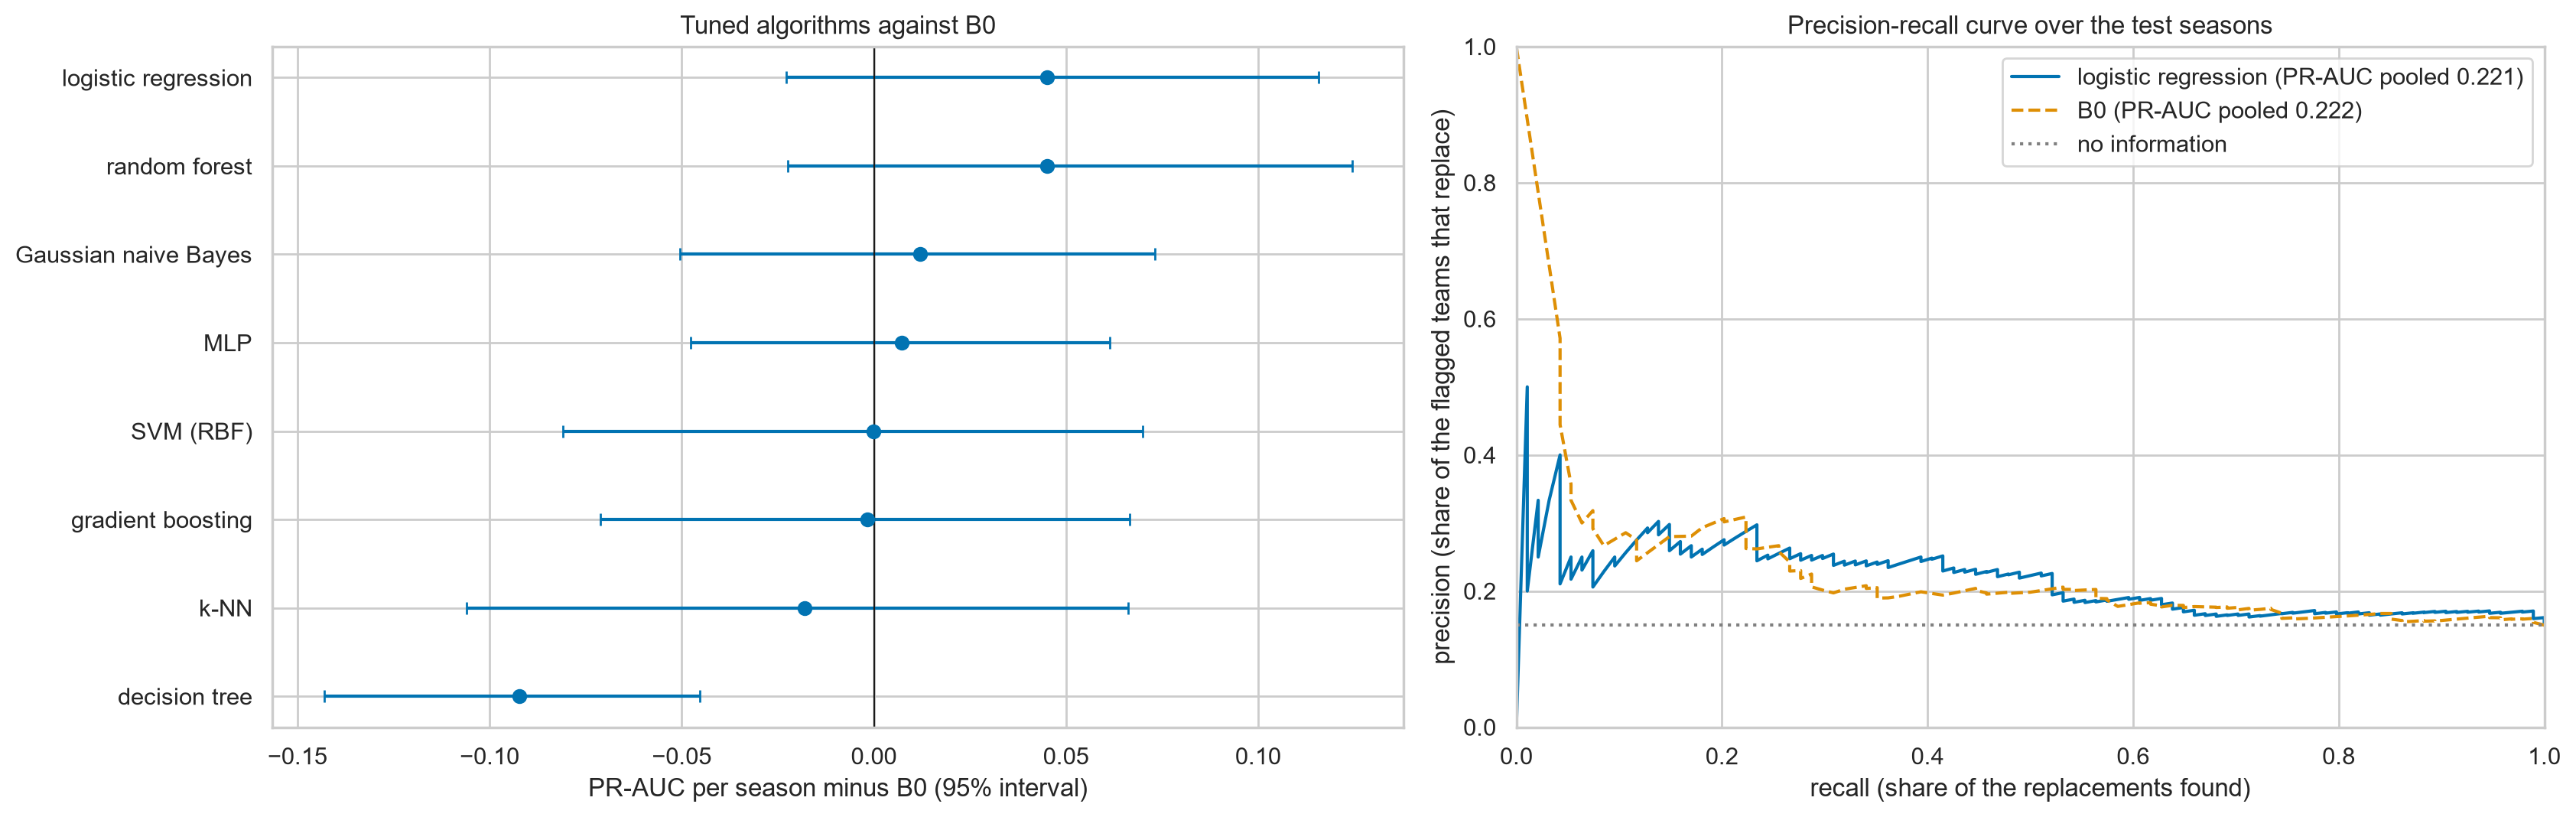

In [13]:
results = compare({**{n: r["preds"] for n, r in TUNED.items()}, "B0 worst last season first": BASELINES["B0 worst last season first"]},
                  B0_SEASONS["pr_auc"])
results["seconds per season"] = pd.Series({n: r["folds"]["seconds"].mean() for n, r in TUNED.items()})
results.insert(0, "family", [ALGORITHMS[n][0] if n in ALGORITHMS else "baseline" for n in results.index])
tuned_seasons = pd.DataFrame({n: summary(r["preds"])[0]["pr_auc"] for n, r in TUNED.items()})
friedman = stats.friedmanchisquare(*[tuned_seasons[c] for c in tuned_seasons])
BEST = results.drop(index="B0 worst last season first")["PR-AUC per season"].idxmax()

fig, ax = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})
forest(ax[0], results.drop(index="B0 worst last season first"), "Tuned algorithms against B0", "B0")
d = META.rename(columns={LABEL: "y"})
for name, preds, style in [(BEST, TUNED[BEST]["preds"], "-"), ("B0", BASELINES["B0 worst last season first"], "--")]:
    m = d.merge(preds, on=["year", "tmID"])
    precision, recall, _ = precision_recall_curve(m["y"], m["score"])
    ax[1].plot(recall, precision, ls=style, label=f"{name} (PR-AUC pooled {average_precision_score(m['y'], m['score']):.3f})")
ax[1].axhline(d.loc[d["year"].isin(TEST_YEARS), "y"].mean(), color="grey", ls=":", label="no information")
ax[1].set(title="Precision-recall curve over the test seasons", xlabel="recall (share of the replacements found)",
          ylabel="precision (share of the flagged teams that replace)", xlim=(0, 1), ylim=(0, 1))
ax[1].legend()
plt.tight_layout()
print(f"Friedman test over the {tuned_seasons.shape[1]} algorithms and {len(tuned_seasons)} seasons: chi2 = {friedman.statistic:.1f}, p = {friedman.pvalue:.3f}")
print(f"best by PR-AUC per season: {BEST}")
results.sort_values("PR-AUC per season", ascending=False).round(3)

- **No algorithm is significantly better than B0.** The best two, the logistic regression and the random forest, reach a PR-AUC per season of 0.358 against 0.313 (+0.045, 14% more), better in 15 and 13 of the 24 seasons. The interval includes zero (−0.023 to +0.116), and the Wilcoxon p is 0.39 (1.0 after Holm).
- **At the top of the list they find about as many replacements as B0** (precision@4 0.26 against 0.25), and they rank all the teams a little better (ROC-AUC 0.613 against 0.594). Pooled over the seasons, B0's very first flags are the most precise (curve): the teams with the very worst record of their season are the safest bets, while the models' probabilities come from 24 different training sets and are less comparable from one season to the next.
- **The single tree is significantly worse than B0** (−0.092, better in 7 of 24 seasons, p = 0.003, 0.02 after Holm). The Friedman test finds that the algorithms differ (p < 0.001), mostly because of it. k-NN, boosting and the SVM are at the level of B0.
- **The family decides more than the tuning.** The models that average or smooth (logistic regression, forest, naive Bayes, MLP) are above B0, and those that cut the data into small regions (single tree, k-NN) are below it. With about 25 replacements in 6 validation seasons, a rule learned from a small region is mostly noise.
- **Against the success criteria (01, section 1)**, B0 had a ROC-AUC of 0.59, a PR-AUC of 0.22, and its 4 flagged teams caught 24% of the changes (25.5% here). The logistic regression reaches 0.61, 0.22 and 27%: a small improvement of the ranking, not a different level. This is the limit the EDA expected (01, 6.2): the median replacement comes after 36 games, so most of what decides it happens after the eve.
- **On time**, the logistic regression costs about 14 s per season to tune and train, against about 110 s for the forest that scores the same. It is the model to keep.

## 8. Overfitting

For the setting that tuning chose in each split: the PR-AUC per season on the seasons the model was trained on, on the validation seasons that chose it, and on the season it never saw.

,train,validation (chosen setting),test,train - test,validation - test
decision tree,0.445,0.326,0.220,0.224,0.106
k-NN,1.000,0.392,0.295,0.705,0.097
gradient boosting,0.578,0.402,0.311,0.267,0.091
SVM (RBF),0.500,0.410,0.312,0.188,0.098
MLP,0.521,0.413,0.320,0.201,0.093
Gaussian naive Bayes,0.417,0.358,0.325,0.093,0.034
random forest,0.750,0.425,0.358,0.392,0.067
logistic regression,0.463,0.413,0.358,0.105,0.056


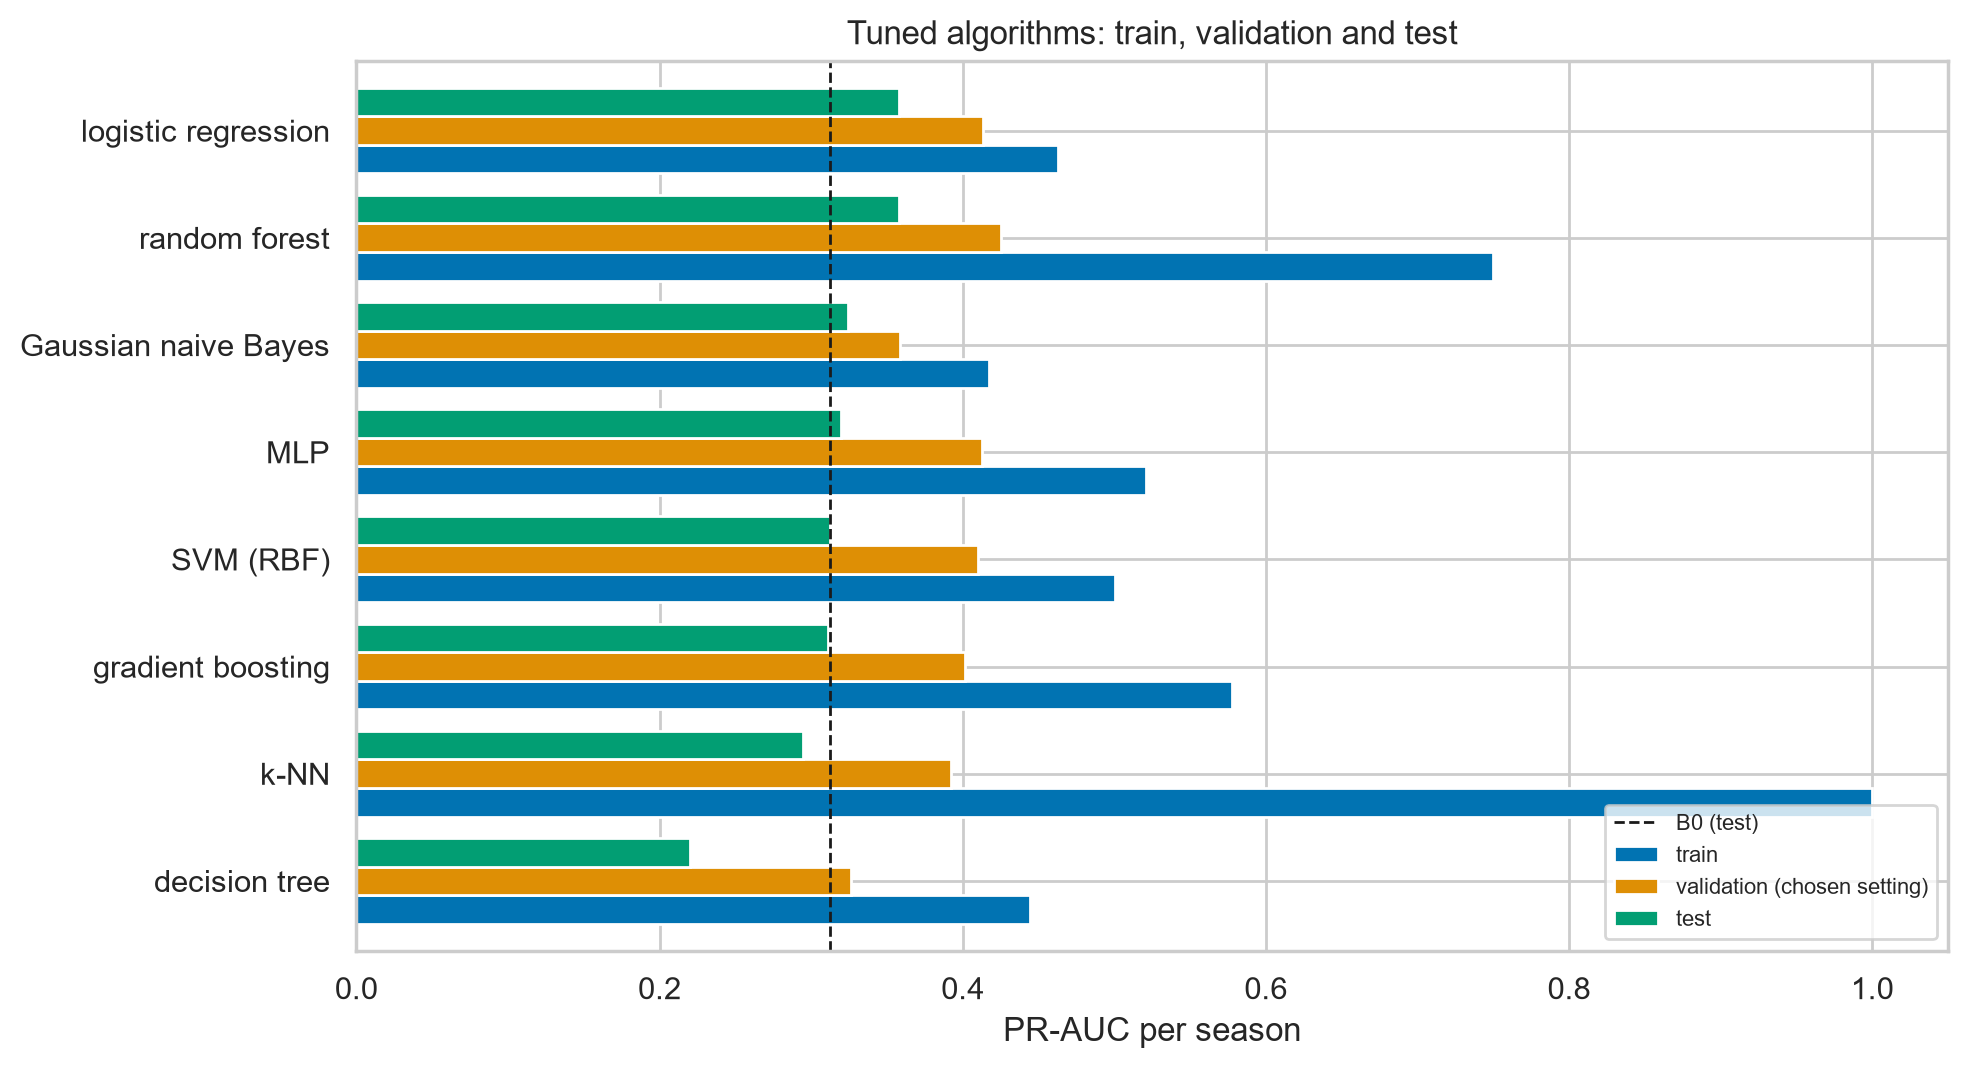

In [14]:
gap = pd.DataFrame({n: {"train": r["folds"]["train"].mean(), "validation (chosen setting)": r["folds"]["inner"].mean(),
                        "test": tuned_seasons[n].mean()} for n, r in TUNED.items()}).T.sort_values("test")
ax = gap.plot.barh(figsize=(10, 5.5), width=0.8)
ax.axvline(B0_SEASONS["pr_auc"].mean(), color="k", ls="--", lw=1, label="B0 (test)")
ax.set(title="Tuned algorithms: train, validation and test", xlabel="PR-AUC per season")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
gap.assign(**{"train - test": gap["train"] - gap["test"], "validation - test": gap["validation (chosen setting)"] - gap["test"]}).round(3)

- **Every algorithm scores higher on its training seasons than on validation, and higher on validation than on test.** Validation is above test by 0.03 to 0.11: the setting chosen is the best of 8 to 48 on 6 noisy seasons, partly the luckiest one, so a validation score can't be reported as a result (as in 03).
- **k-NN memorises its training rows** (1.0: with distance weights a team-season is its own nearest neighbour), and the forest fits them closely (0.75), so their training scores say nothing. The forest still generalises as well as the logistic regression, because averaging 200 trees removes most of that variance.
- **The smallest gaps are the simplest models**: naive Bayes (0.09 between train and test) and the logistic regression (0.10), which also has the best test score, tied with the forest.
- **The tree overfits its validation seasons the most** (0.11 above test) with the deepest setting of its grid: depth 5 with leaves of 10 rows, on a few hundred rows with 50 to 140 replacements, is enough to memorise noise.

## 9. What the models learned

### 9.1 Feature importance

The permutation importance of the best algorithm, on the test seasons: in each split, one feature of the predicted season is shuffled among its teams (20 times), the fitted model scores the teams again, and the importance is the loss of PR-AUC per season. It is measured on seasons the model never saw, and a feature that the selection step left out has an importance of 0 by construction.

,importance,se
pts_pct_z_lag1,4.740e-02,0.025
coach_changed_lag1,4.630e-02,0.021
new_coach,4.060e-02,0.020
playoff_depth_lag1,3.410e-02,0.026
award_before,3.200e-02,0.024
former_player,1.650e-02,0.023
career_win_pct,6.000e-03,0.013
coach_age,5.700e-03,0.017
first_job,5.100e-03,0.006
roster_talent_z,3.000e-03,0.015


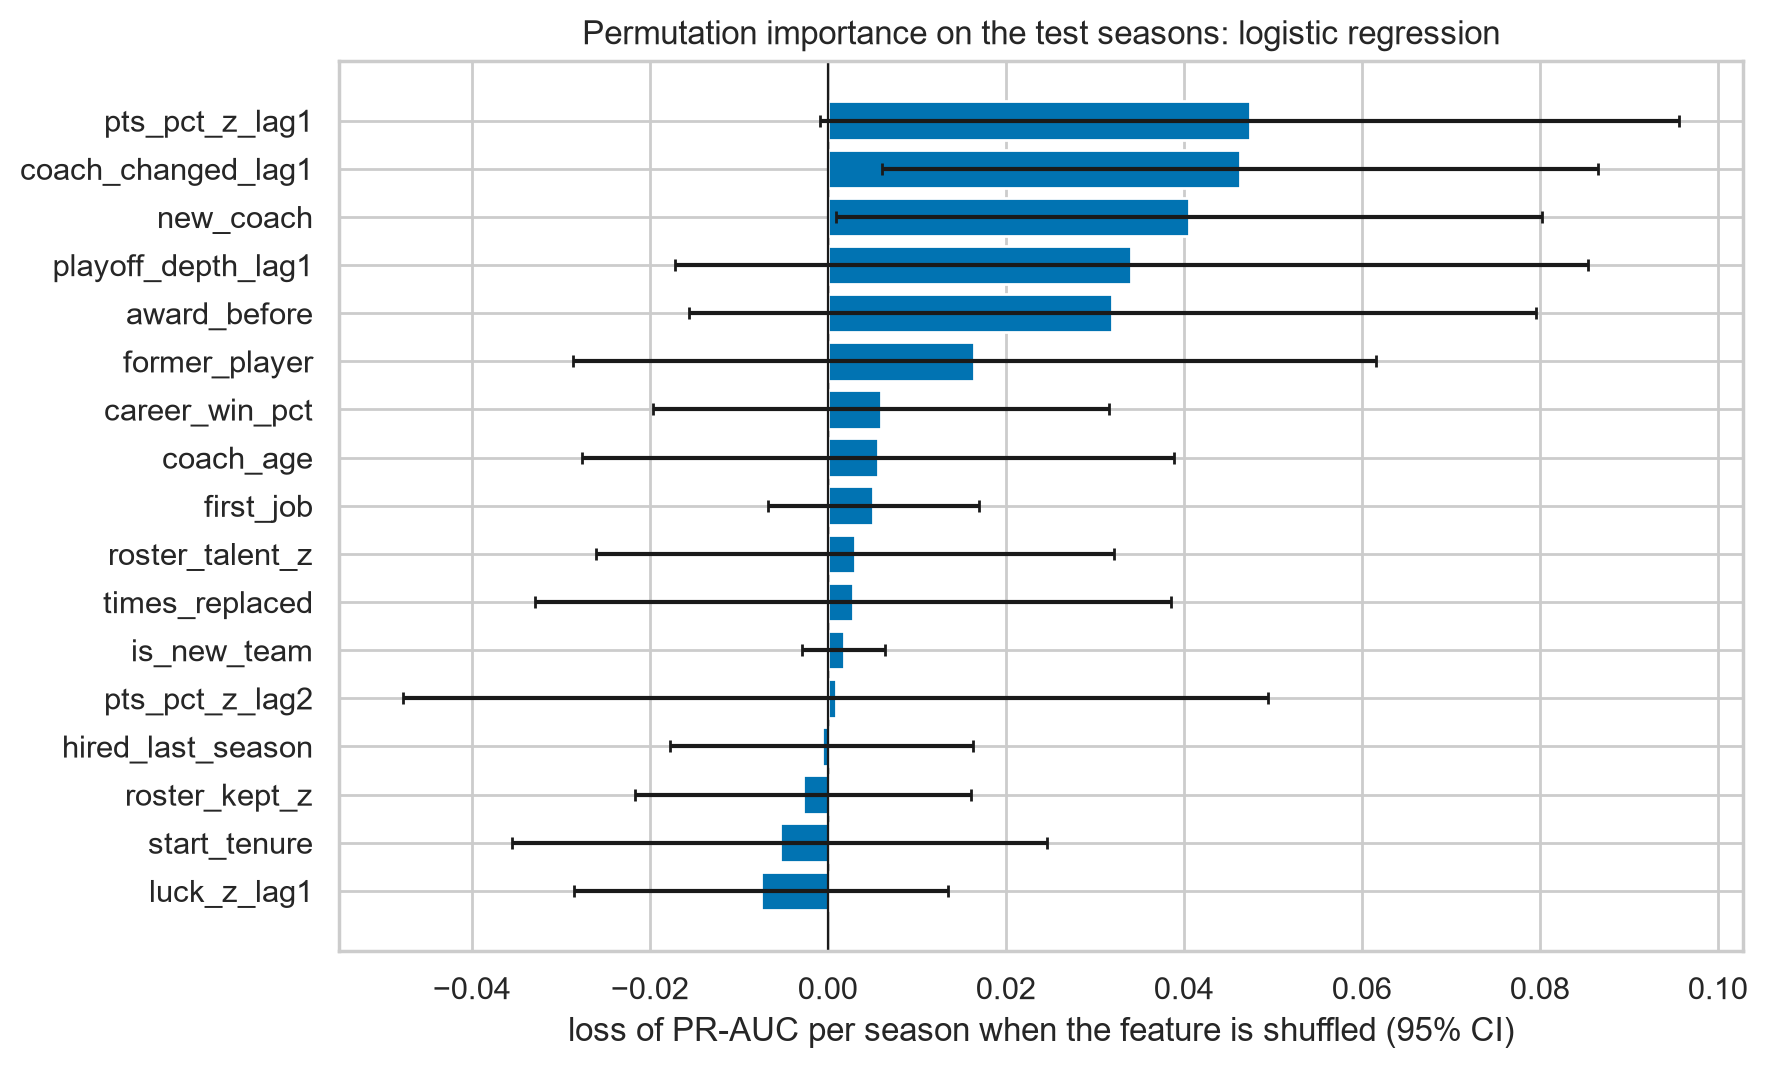

In [15]:
def permutation_importance_walk(run, repeats=20, seed=RANDOM_STATE):
    """Mean loss of PR-AUC per season when one feature of the test season is shuffled, over the splits of `run`."""
    rng = np.random.default_rng(seed)
    base = summary(run["preds"])[0]["pr_auc"]
    out = {}
    for j, f in enumerate(FEATURES):
        losses = []
        for year, est in run["estimators"].items():
            rows = panel[panel["year"] == year]
            X, y = rows[FEATURES].to_numpy(float), rows[LABEL].to_numpy()
            for _ in range(repeats):
                Xp = X.copy()
                Xp[:, j] = rng.permutation(Xp[:, j])
                losses.append(base[year] - average_precision_score(y, scores_of(est, Xp)))
        out[f] = {"importance": np.mean(losses), "se": np.std(losses) / np.sqrt(len(run["estimators"]))}
    return pd.DataFrame(out).T.sort_values("importance", ascending=False)


importance = permutation_importance_walk(TUNED[BEST])
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(importance.index, importance["importance"], xerr=1.96 * importance["se"], color="C0", capsize=2)
ax.invert_yaxis()
ax.axvline(0, color="k", lw=0.8)
ax.set(title=f"Permutation importance on the test seasons: {BEST}", xlabel="loss of PR-AUC per season when the feature is shuffled (95% CI)")
plt.tight_layout()
importance.round(4)

### 9.2 White-box models

**The logistic regression** is a weighted sum: each coefficient, on standardised features, is the change of the log-odds of a replacement for one standard deviation more (or for "yes" in a binary feature). The odds ratios below come from the 24 fitted models of the walk-forward (one per test season), so they also show how stable the weights are over time. A feature that the selection step left out in a split gets an odds ratio of 1 there.

,median odds ratio,min,max
former_player,1.52,1.00,4.90
pts_pct_z_lag2,1.41,1.00,2.19
coach_age,1.12,1.00,1.40
luck_z_lag1,1.10,1.00,1.25
hired_last_season,1.00,0.54,2.22
roster_talent_z,1.00,0.80,1.38
start_tenure,0.98,0.54,1.60
first_job,0.96,0.56,1.11
roster_kept_z,0.95,0.84,1.09
times_replaced,0.84,0.71,1.00


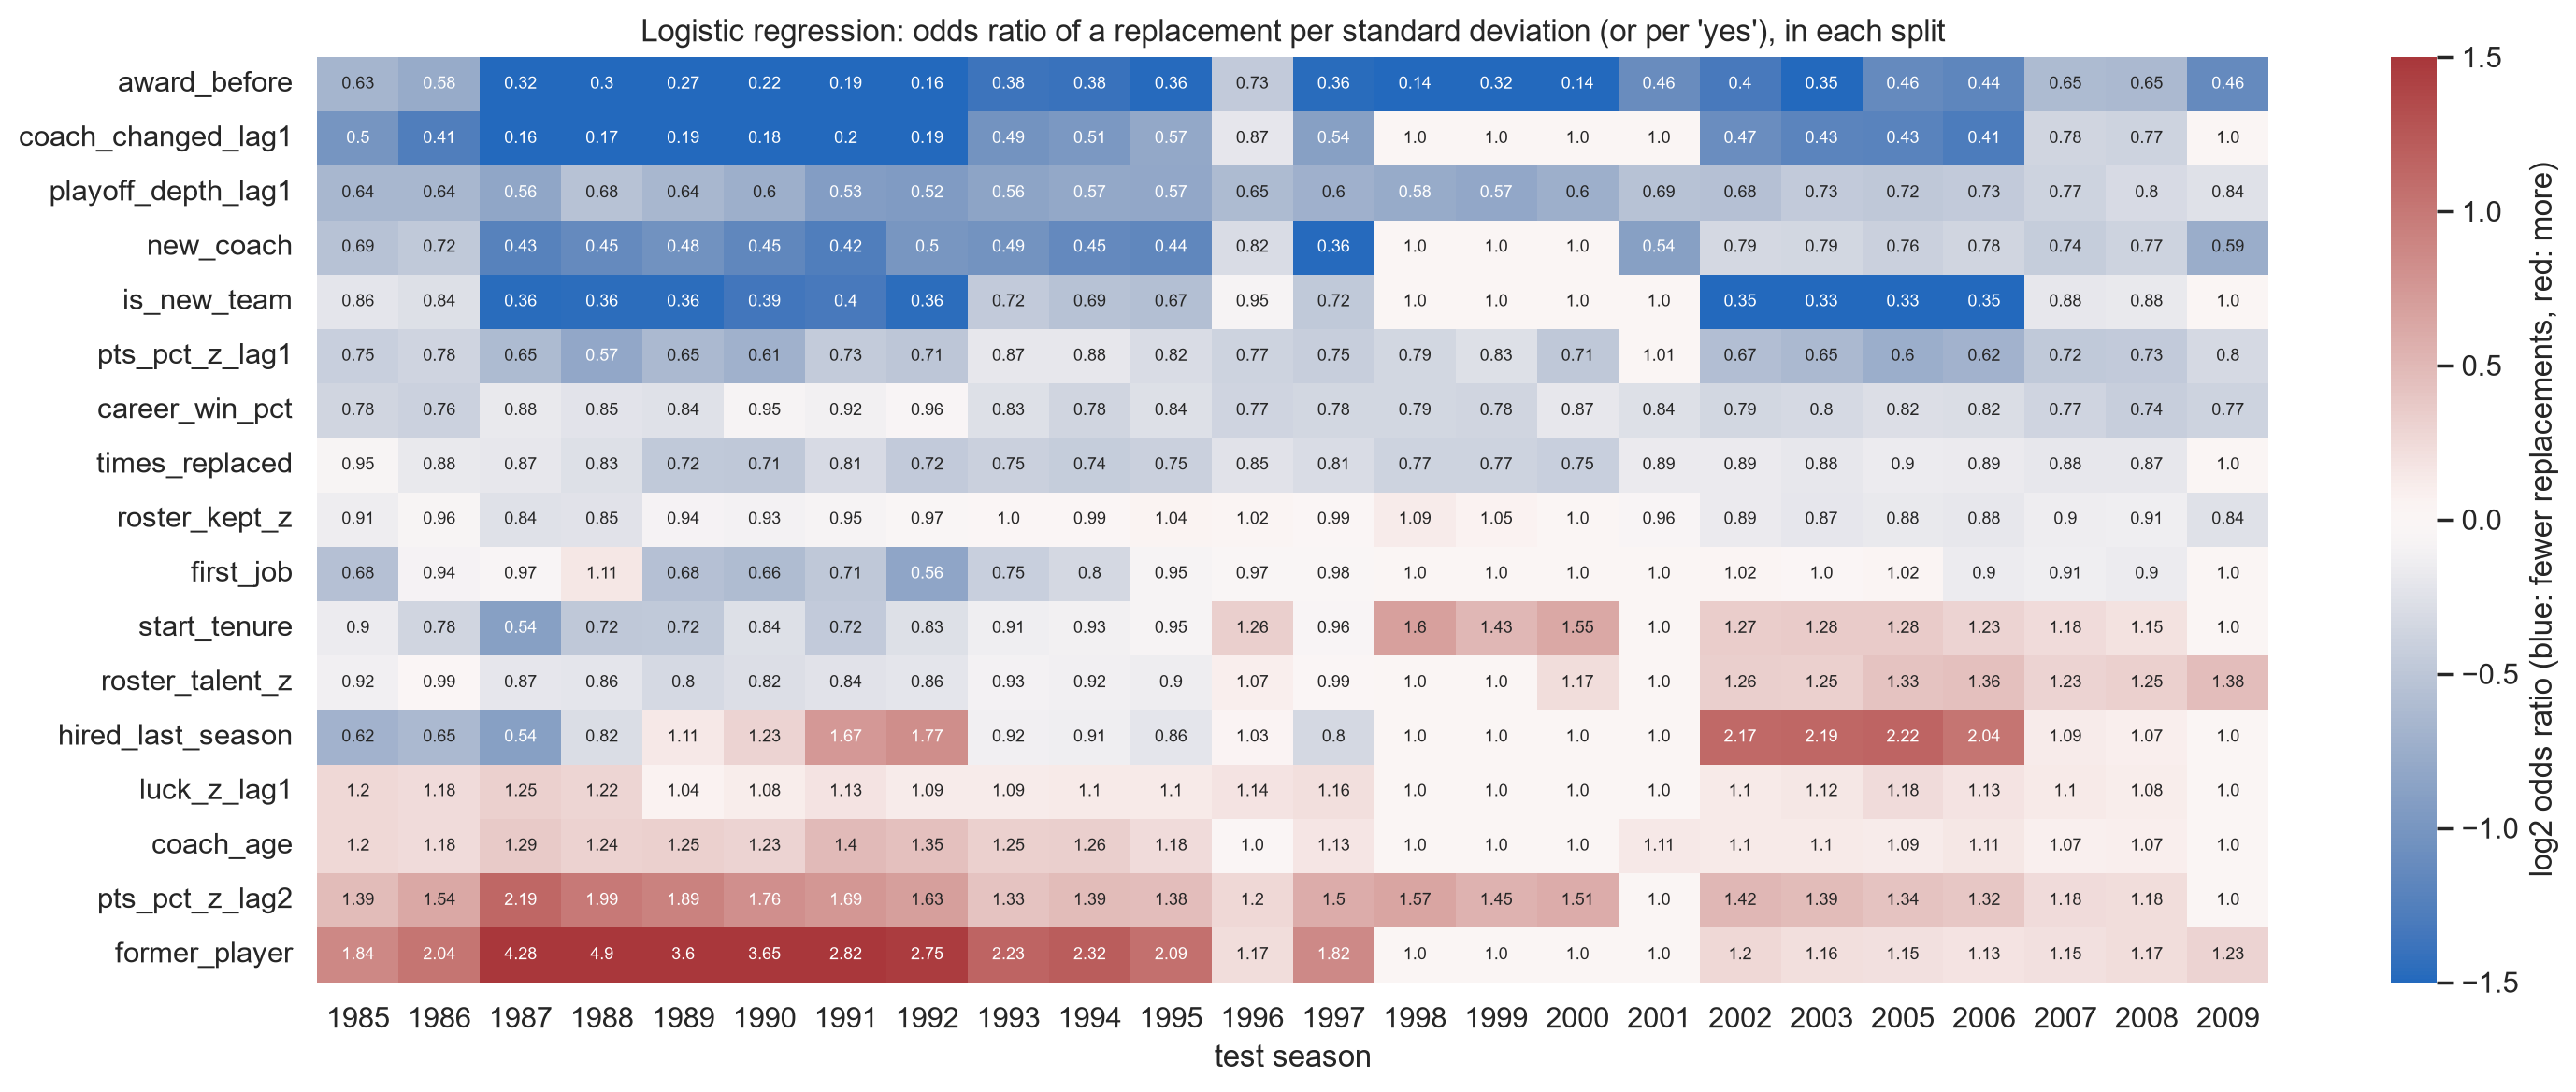

In [16]:
def logistic_odds(run):
    """Odds ratio of every feature in every split (1 when the feature was not selected)."""
    rows = {}
    for year, est in run["estimators"].items():
        sel = est.named_steps["select"]
        mask = sel.get_support() if hasattr(sel, "get_support") else np.ones(len(FEATURES), dtype=bool)
        coef = np.zeros(len(FEATURES))
        coef[mask] = est.named_steps["model"].coef_[0]
        rows[year] = np.exp(coef)
    return pd.DataFrame(rows, index=FEATURES)


odds = logistic_odds(TUNED["logistic regression"])
order = np.log(odds).median(axis=1).sort_values().index
fig, ax = plt.subplots(figsize=(15, 6))
sns.heatmap(np.log2(odds.loc[order]), ax=ax, cmap="vlag", center=0, vmin=-1.5, vmax=1.5, annot=odds.loc[order].round(2), fmt="",
            annot_kws={"size": 6.5}, cbar_kws={"label": "log2 odds ratio (blue: fewer replacements, red: more)"})
ax.set(title="Logistic regression: odds ratio of a replacement per standard deviation (or per 'yes'), in each split", xlabel="test season", ylabel="")
plt.tight_layout()
odds.T.describe().T[["50%", "min", "max"]].rename(columns={"50%": "median odds ratio"}).loc[order[::-1]].round(2)

**A decision tree** with 3 levels, fitted on all the seasons 1974–2009, shows the rules that separate the team-seasons with a replacement. It is the model a club could use for the next season (2010), read as a set of rules. Its leaves show the share of replacements (class weights balanced, so 0.5 means the base rate).

,team-seasons,replaced,share
4,60,27,0.450
7,32,10,0.312
3,102,26,0.255
11,329,57,0.173
10,188,18,0.096
13,35,3,0.086
6,50,3,0.060
14,46,0,0.000


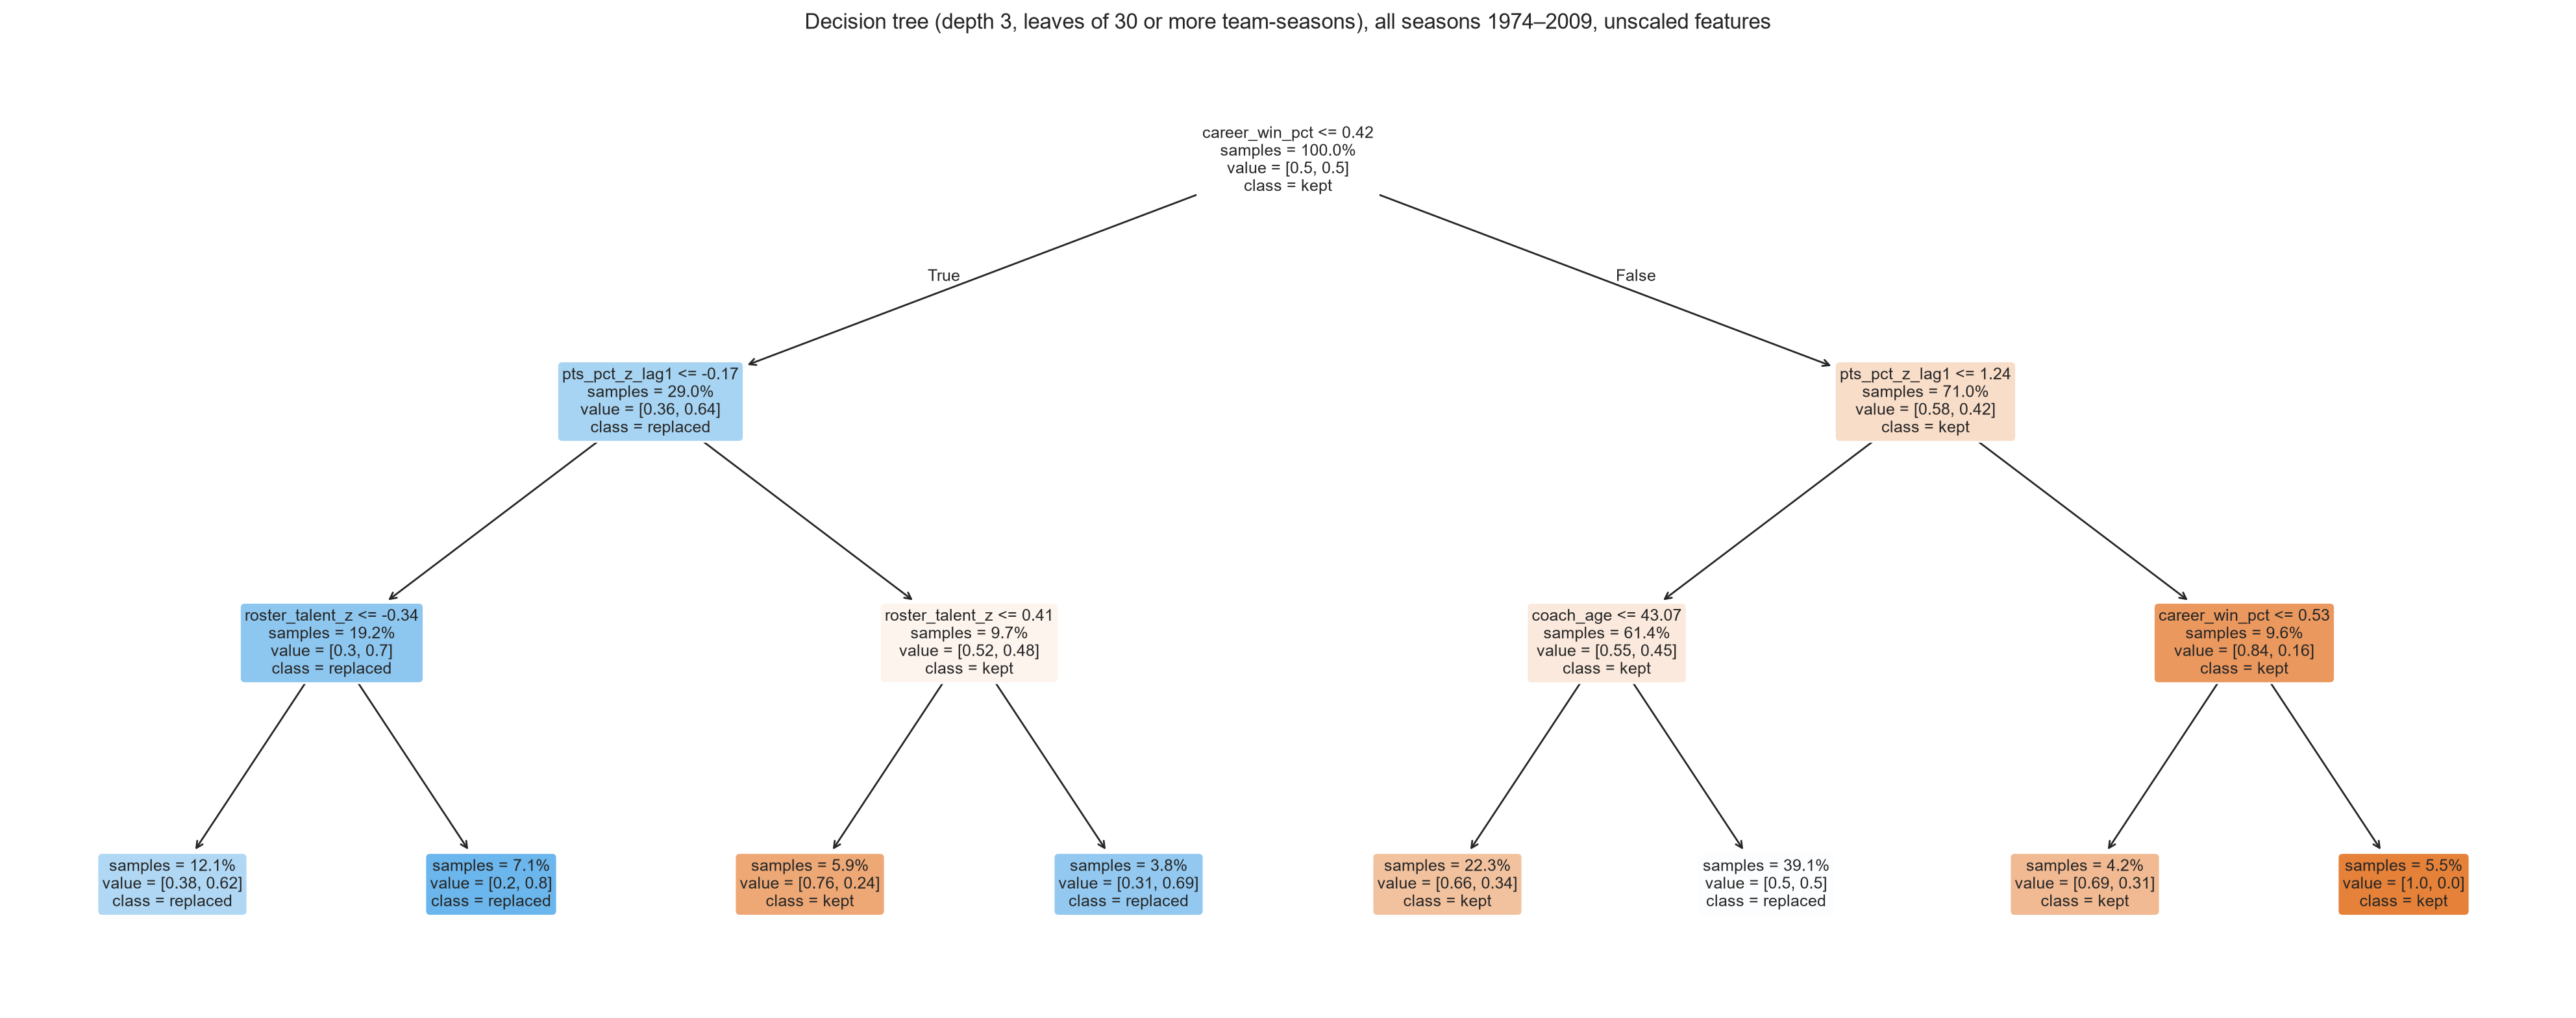

In [17]:
raw = panel[FEATURES].copy()
raw[CONT] = raw[CONT].fillna(raw[CONT].median())
raw[BIN] = raw[BIN].fillna(raw[BIN].mode().iloc[0])
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=30, class_weight="balanced", random_state=RANDOM_STATE).fit(raw, panel[LABEL])
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(tree, feature_names=FEATURES, class_names=["kept", "replaced"], filled=True, rounded=True, proportion=True, impurity=False,
          precision=2, fontsize=9, ax=ax)
ax.set_title("Decision tree (depth 3, leaves of 30 or more team-seasons), all seasons 1974–2009, unscaled features")
plt.tight_layout()
leaf = tree.apply(raw)
pd.DataFrame({"team-seasons": pd.Series(leaf).value_counts(), "replaced": pd.Series(panel[LABEL].to_numpy()).groupby(leaf).sum()}).assign(
    share=lambda d: d["replaced"] / d["team-seasons"]).sort_values("share", ascending=False).round(3)

**Feature importance (9.1)**
- **Five features carry the logistic regression**: last season's points % (shuffling it costs 0.047 of PR-AUC per season), an in-season change last season (0.046), a new coach (0.041), the playoff depth (0.034) and an award before (0.032). Each is about 2 standard errors from 0, so their order is uncertain, but together they are the model: two about the team's results and three about the coach's situation.
- **The rest adds nothing measurable on the test seasons**, including the career win % (0.006), which the EDA found to be the strongest coach driver (01, 6.2). An award before and last season's results carry most of the same information: a coach with a good record has usually won an award (0.5) and coaches a good team (0.7, 02, section 7).

**Logistic regression (9.2)**
- **An award protects the coach.** A coach who has already won an award (mostly the Jack Adams) has 0.37 times the odds of a replacement of one who hasn't (median of the 24 models; 0.14 to 0.73). A club gives a proven coach more patience, as in 01, 6.2.
- **A recent change protects the next coach.** After an in-season change last season the odds are about halved (0.49), and a coach new this season has 0.64 times the odds: the "honeymoon" that the EDA saw in its survival curves (01, 6.2), and it holds in every split.
- **Bad results raise the risk, and a decline raises it more.** One standard deviation more of points % last season lowers the odds to 0.73, and one more of playoff depth to 0.64. With last season fixed, a team that was better *two* seasons ago is at more risk (1.41 per standard deviation): a fall, not only a poor level, is what costs a coach the job.
- **Former NHL players are replaced more often** (1.52, up to 4.9 in 1987–92 and weaker from 1996). The raw rates are close (18% against 15%) and the EDA found no significant effect (01, 6.2), so this is a weak signal to read with care.
- **The weights move over time**, and their size also depends on the penalty chosen in each split; where the filter was chosen (1998–2001) several features were left out (odds ratio 1). The direction of the main effects (award, recent change, results, decline) is the same in every split.

**Decision tree (9.2)**
- **The first question is the coach's record**: a career win % of 0.42 or less (29% of the team-seasons). First-time coaches have no record; filled with the median (0.456), they go to the other side.
- **A losing coach of a poor team whose roster is not hopeless has the highest risk**: 45% of these 60 team-seasons replaced the coach, three times the base rate. With an even weaker roster it is 25%. The same holds for losing coaches of better teams: 31% with a strong roster against 6% without. Our reading: when the roster is clearly poor the club accepts the results and keeps the coach, and when it isn't, the coach takes the blame. A linear model can't express this interaction.
- **Winning coaches of the best teams are never replaced**: 0 of 46 team-seasons with a career win % above 0.53 and a team more than 1.24 standard deviations above the league last season.
- **Among the rest (61% of the rows), age splits the risk**: 17% for coaches older than 43, 10% for the younger ones.
- As a predictor this tree is weak (section 7). It is a description of the data, read as rules, and it tells the same story as the logistic regression: the coach's record, the team's level, and the expectations the roster creates.

## 10. Conclusions, limitations and future work

**Conclusions**
- **The best models for task (b) are the logistic regression and the random forest**, with a PR-AUC per season of 0.358 against 0.313 for B0. The gain, +0.045, is not significant over 24 seasons: on the eve of a season, last season's record already says most of what can be known. The logistic regression is the one to keep: as good as the forest, about eight times faster to tune and train, and readable.
- **What the models add to B0 is the coach's situation**: an award before, a recent change (the honeymoon), and a decline from two seasons ago.
- **Data preparation inside the folds**: over-sampling (SMOTE-NC) helps a little and the training seasons choose it in most splits; the imputer and the outlier treatments don't matter; the wrapper selection overfits the small validation seasons and is worse than keeping all the features.
- **A training sample of about 5 seasons is needed**, and more seasons don't hurt.

**Limitations**
- **Few events.** There are 94 replacements in the 24 test seasons, 2 to 7 per season, so the per-season scores are noisy and only large differences can be significant.
- **The label.** The strict threshold of 10 games is a choice (01, 5.4). A replacement often follows events of the season itself (injuries, a bad start), which no feature known on the eve can see; the median replacement comes after 36 games (01, 6.2).
- **The starting roster** is approximated by the first stints (02, section 5.3).
- **Few validation seasons.** The tuned settings are unstable and the validation scores optimistic.
- **The comparisons of section 5 use the test seasons**, so they describe effects but don't choose anything; section 6 doesn't depend on them.

**Future work**
- Tune the training window inside the training seasons (section 4 found 5 to 8 seasons at least as good as all of them).
- Calibrate the probabilities on the training seasons, so that the pooled measures and a threshold for flagging a team make sense across seasons.
- Information the data doesn't have: the coach's contract, the injuries of the roster, the changes in the club's management.
- If predictions during the season were allowed, model the timing of the replacement (survival models with the games already played).